# NACA0012 POD–PINN: complete reproducible workflow

This notebook reproduces both approaches used in the project:

1. Fixed-weight POD–PINNs with 32×32, 64×64, and 128×128 hidden layers.
2. A self-adaptive-weight 64×64 POD–PINN.

The workflow uses the native CFD mesh for POD/data truth and a validated Delaunay structured grid for physics derivatives. Read `README_TA.md` before the first run.

## 0. Runtime control

Leave `RETRAIN_MODELS=True` for a full reproduction. Change it to `False` for a fast audit using the included checkpoints.

In [ ]:
from pathlib import Path
import json, os, platform, subprocess, sys, time
import numpy as np

ROOT = Path.cwd().resolve()
if (ROOT / 'POD_PINN_Clean').is_dir():
    PROJECT = ROOT / 'POD_PINN_Clean'
elif (ROOT / 'preprocess_pod.py').is_file():
    PROJECT = ROOT
    ROOT = PROJECT.parent
else:
    raise FileNotFoundError('Run this notebook from the extracted package root.')
DATA = ROOT / 'NACA0012_PINN_Study' / 'data' / 'native'
assert DATA.is_dir(), f'Missing source arrays: {DATA}'
RETRAIN_MODELS = True
print('Package root:', ROOT)
print('Project:', PROJECT)
print('Python:', sys.version.split()[0], platform.platform())
print('Retrain models:', RETRAIN_MODELS)

## 1. Dependency and dataset audit

In [ ]:
import scipy, matplotlib, torch
print('NumPy', np.__version__)
print('SciPy', scipy.__version__)
print('Matplotlib', matplotlib.__version__)
print('PyTorch', torch.__version__)

manifest = json.loads((DATA / 'manifest.json').read_text())
train = [row for row in manifest if row['id'].startswith('T')]
validation = [row for row in manifest if row['id'].startswith('V')]
mesh_hashes = {row['mesh_sha256'] for row in manifest}
print(f'Cases: {len(train)} training + {len(validation)} validation')
print('Common mesh:', len(mesh_hashes) == 1)
print('Solver-converged:', sum(bool(row.get('converged')) for row in manifest), '/', len(manifest))
print('Conservative force-stable:', sum(bool(row.get('force_stable')) for row in manifest), '/', len(manifest))
assert len(train) == 40 and len(validation) == 8 and len(mesh_hashes) == 1

## 2. Cell-volume-weighted POD

The POD is fitted only to the 40 training cases. Rank 25 is fixed for all neural-network experiments.

In [ ]:
def run_script(name):
    path = PROJECT / name
    print(f'\n--- Running {name} ---')
    subprocess.run([sys.executable, str(path)], cwd=PROJECT, check=True)

run_script('preprocess_pod.py')

## 3. Delaunay interpolation and physics-operator validation

This stage runs a manufactured derivative test, audits discrete residuals on all 48 CFD cases, and builds the fixed wall-safe collocation operator.

In [ ]:
run_script('validate_delaunay_operator.py')
run_script('build_pod_pinn_operator.py')

## 4. Fixed-weight POD–PINNs

Loss multipliers are fixed at data/continuity/momentum/boundary = 1/1/1/1. Each model uses `tanh`, L-BFGS only, L2=`1e-4`, and 500 optimizer iterations.

In [ ]:
fixed_checkpoint = PROJECT / 'artifacts/models/pod_pinn_2x64_rank25.pt'
if RETRAIN_MODELS or not fixed_checkpoint.exists():
    run_script('train_fixed_pod_pinn.py')
else:
    print('Reusing included fixed-weight checkpoints.')

## 5. Self-adaptive 64×64 POD–PINN

The four positive global weights are learned jointly with the network using bounded uncertainty weighting: $L=\sum_i[e^{-s_i}L_i+s_i]+10^{-4}\lVert\theta\rVert_2^2$.

In [ ]:
adaptive_checkpoint = PROJECT / 'artifacts/models/pod_pinn_2x64_rank25_self_adaptive.pt'
if RETRAIN_MODELS or not adaptive_checkpoint.exists():
    run_script('train_self_adaptive_pod_pinn.py')
else:
    print('Reusing included self-adaptive checkpoint.')

## 6. Recreate metrics and figures

In [ ]:
run_script('make_results.py')
run_script('make_self_adaptive_results.py')
run_script('make_extended_analysis.py')

## 7. Held-out validation summary

In [1]:
fixed = json.loads((PROJECT / 'artifacts/models/pod_pinn_2x64_rank25_metrics.json').read_text())
adaptive = json.loads((PROJECT / 'artifacts/models/pod_pinn_2x64_rank25_self_adaptive_metrics.json').read_text())
print('Field       Fixed 64x64    Self-adaptive 64x64')
for field in ('u', 'w', 'p', 'nut'):
    a = 100*fixed['validation_field_relative_l2'][field]
    b = 100*adaptive['validation_field_relative_l2'][field]
    print(f'{field:<5}       {a:>8.3f}%              {b:>8.3f}%')
fixed_mean = 100*np.mean(list(fixed['validation_field_relative_l2'].values()))
adaptive_mean = 100*np.mean(list(adaptive['validation_field_relative_l2'].values()))
print(f'Mean        {fixed_mean:>8.3f}%              {adaptive_mean:>8.3f}%')
print('Learned adaptive weights:', adaptive['learned_loss_weights'])

Field       Fixed 64x64    Self-adaptive 64x64
u              0.111%                 0.117%
w              2.087%                 1.204%
p              2.002%                 1.430%
nut            1.505%                 1.969%
Mean           1.426%                 1.180%


## 8. Main comparison figures

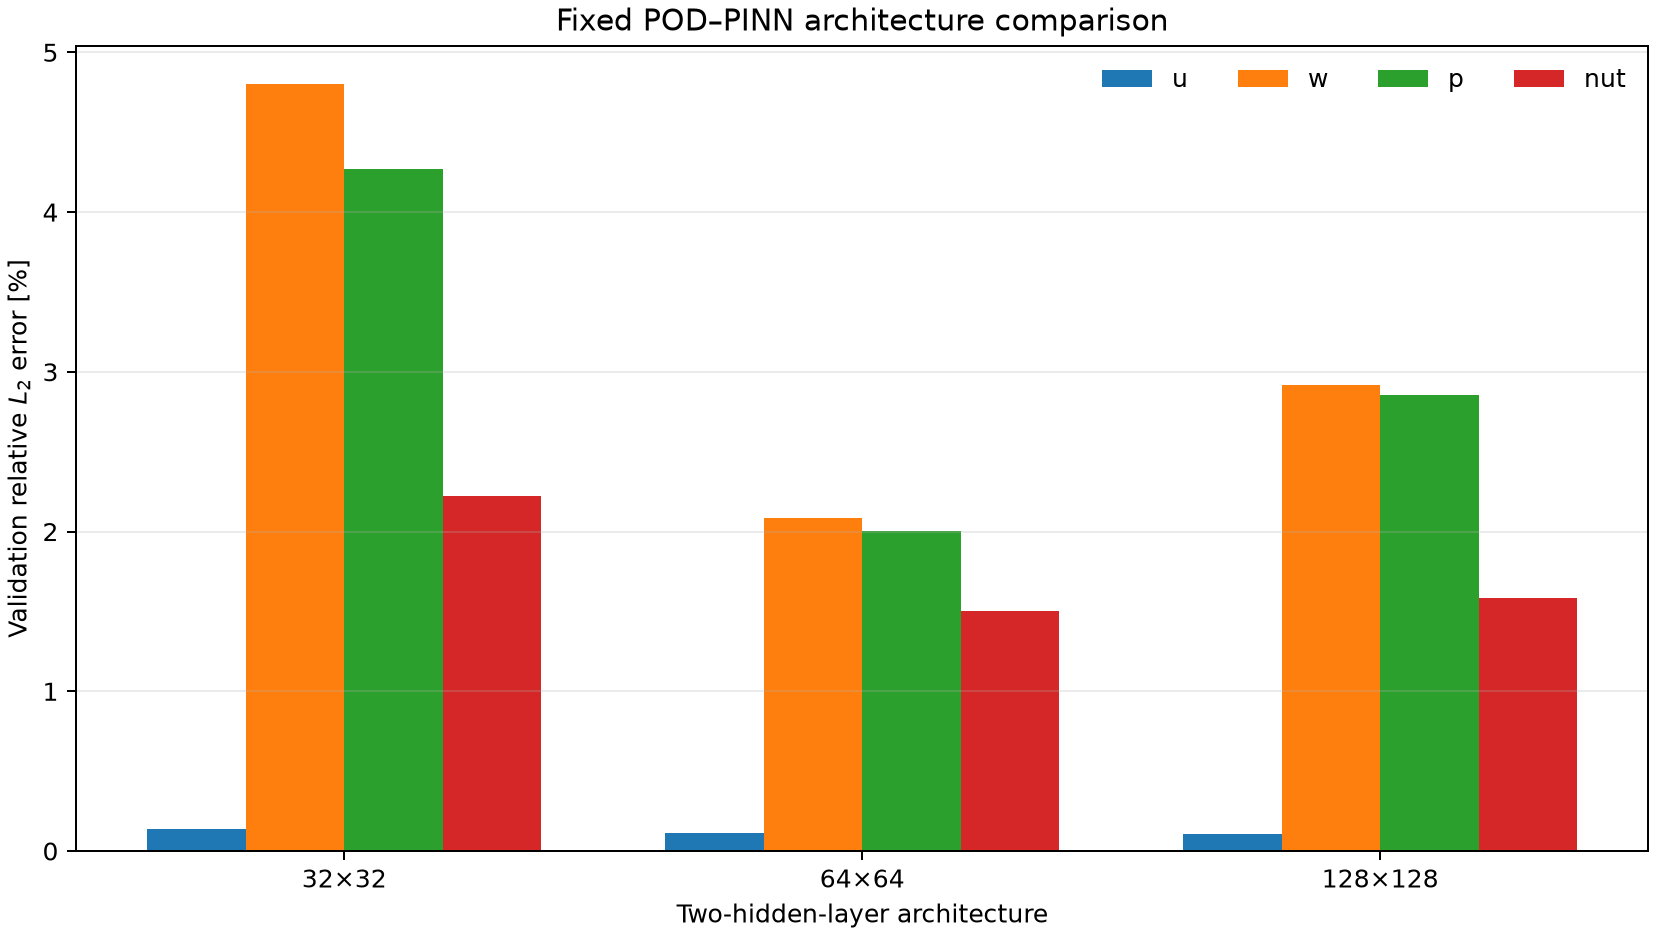

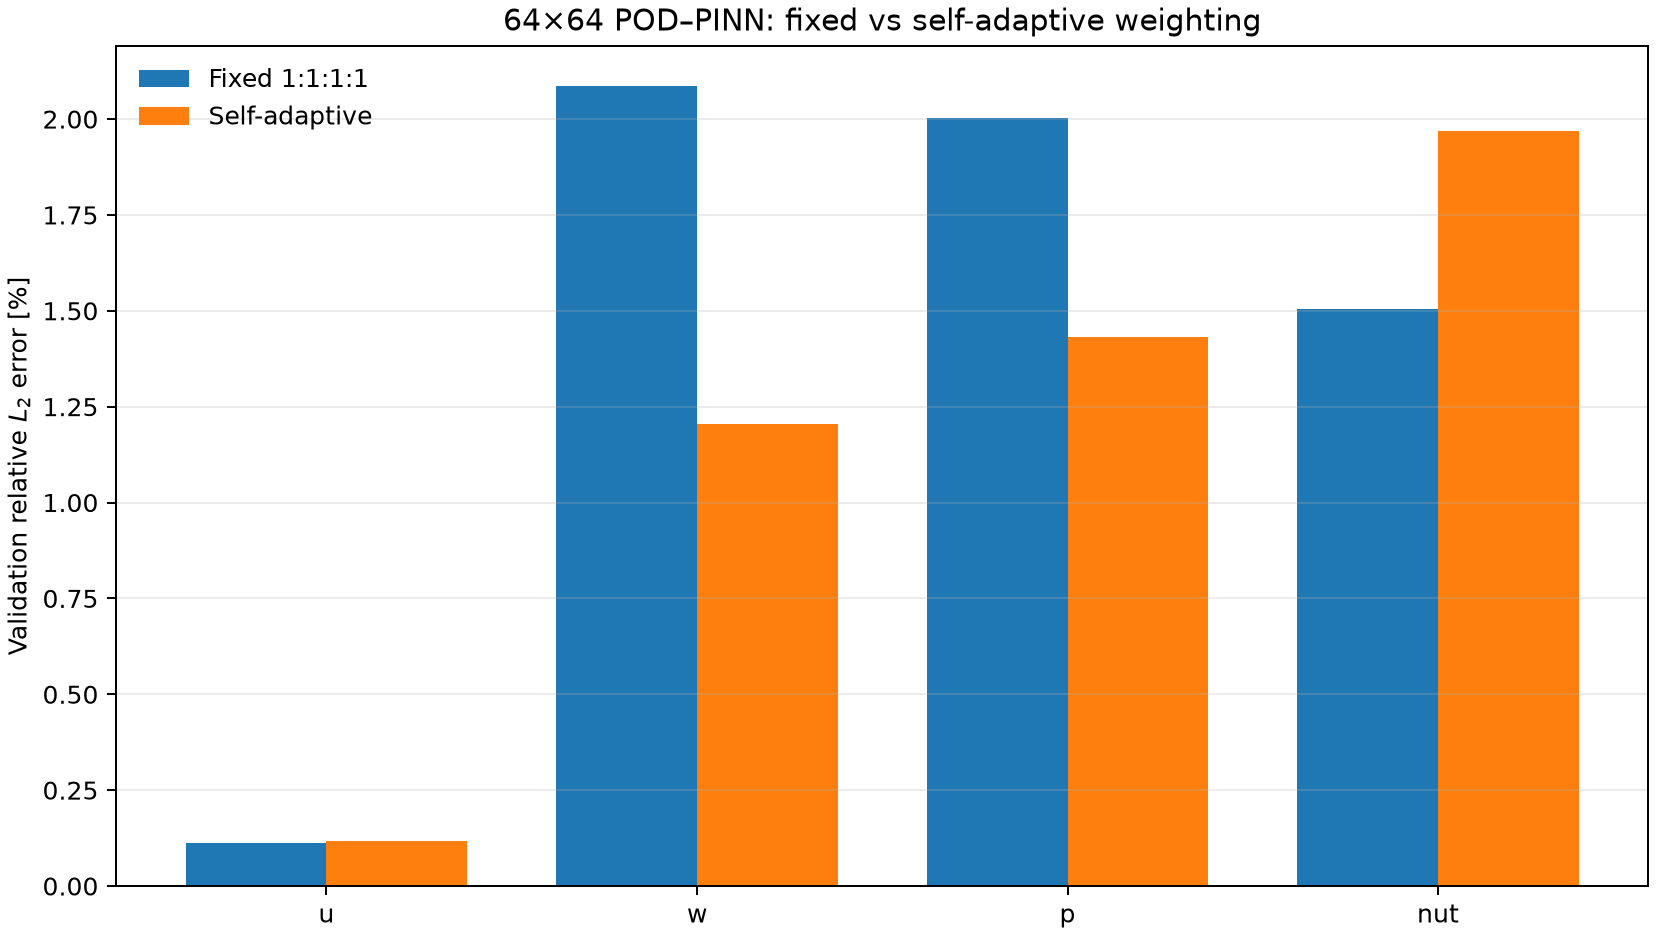

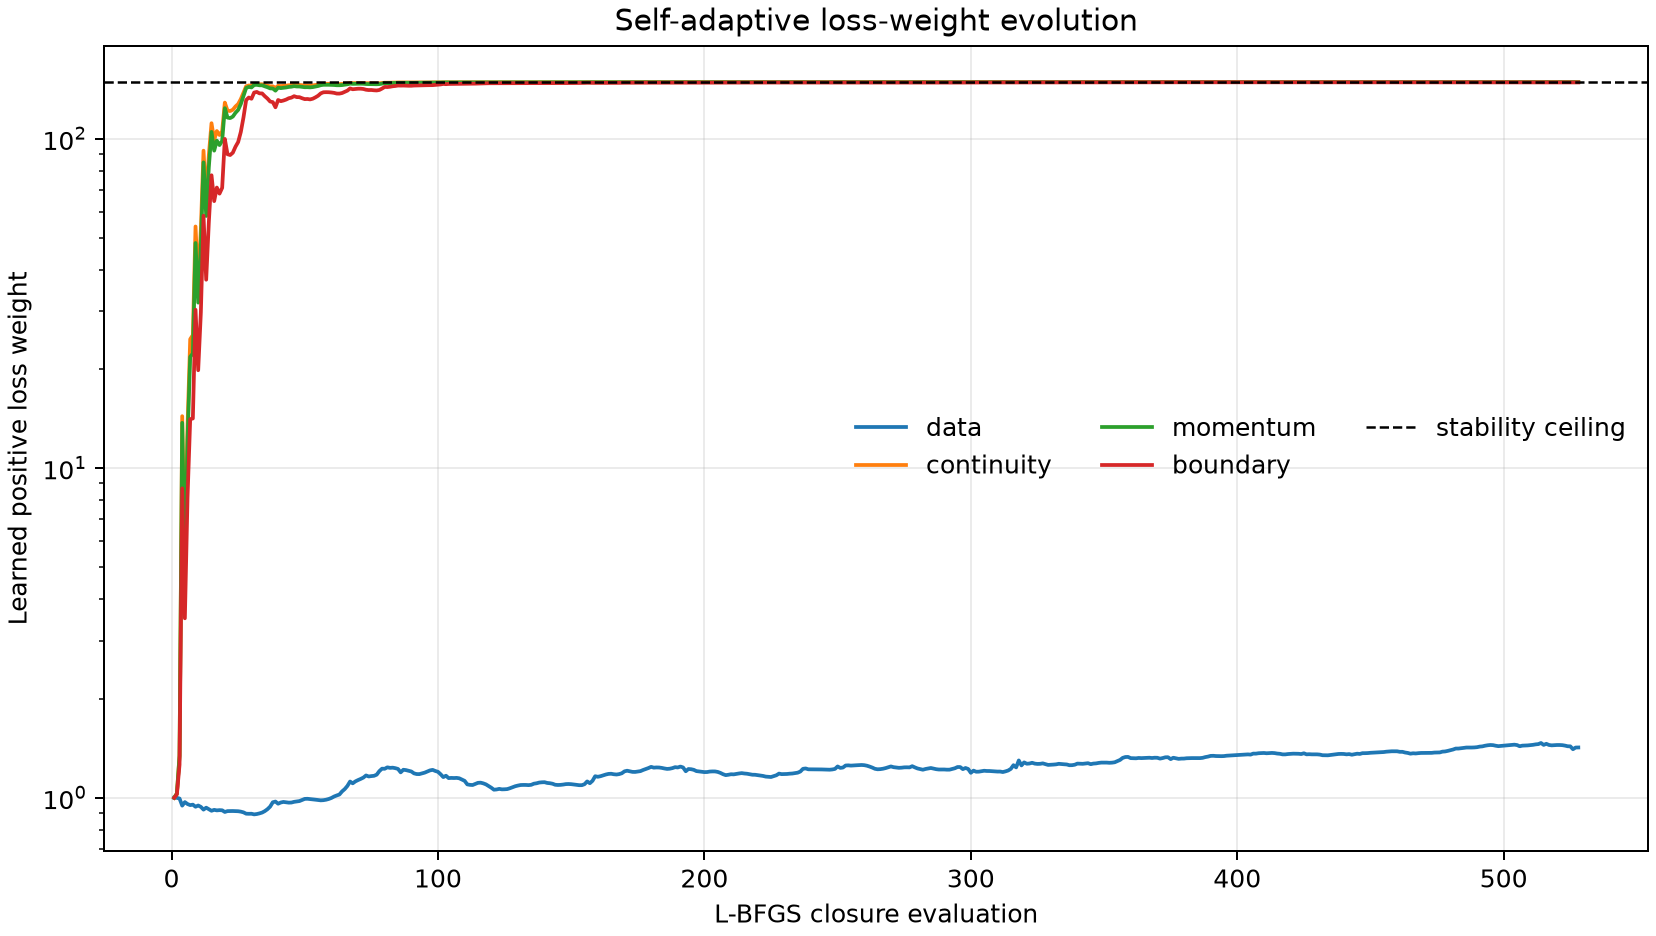

In [2]:
from IPython.display import Image, display
display(Image(filename=str(PROJECT / 'artifacts/results/figures/architecture_comparison.png')))
display(Image(filename=str(PROJECT / 'artifacts/self_adaptive_results/figures/fixed_vs_adaptive_field_errors.png')))
display(Image(filename=str(PROJECT / 'artifacts/self_adaptive_results/figures/adaptive_weight_evolution.png')))

## 9. Aerodynamic analysis

Surface pressure, pressure-derived force parity, and downstream wake profiles expose local behaviour that aggregate field errors cannot show.

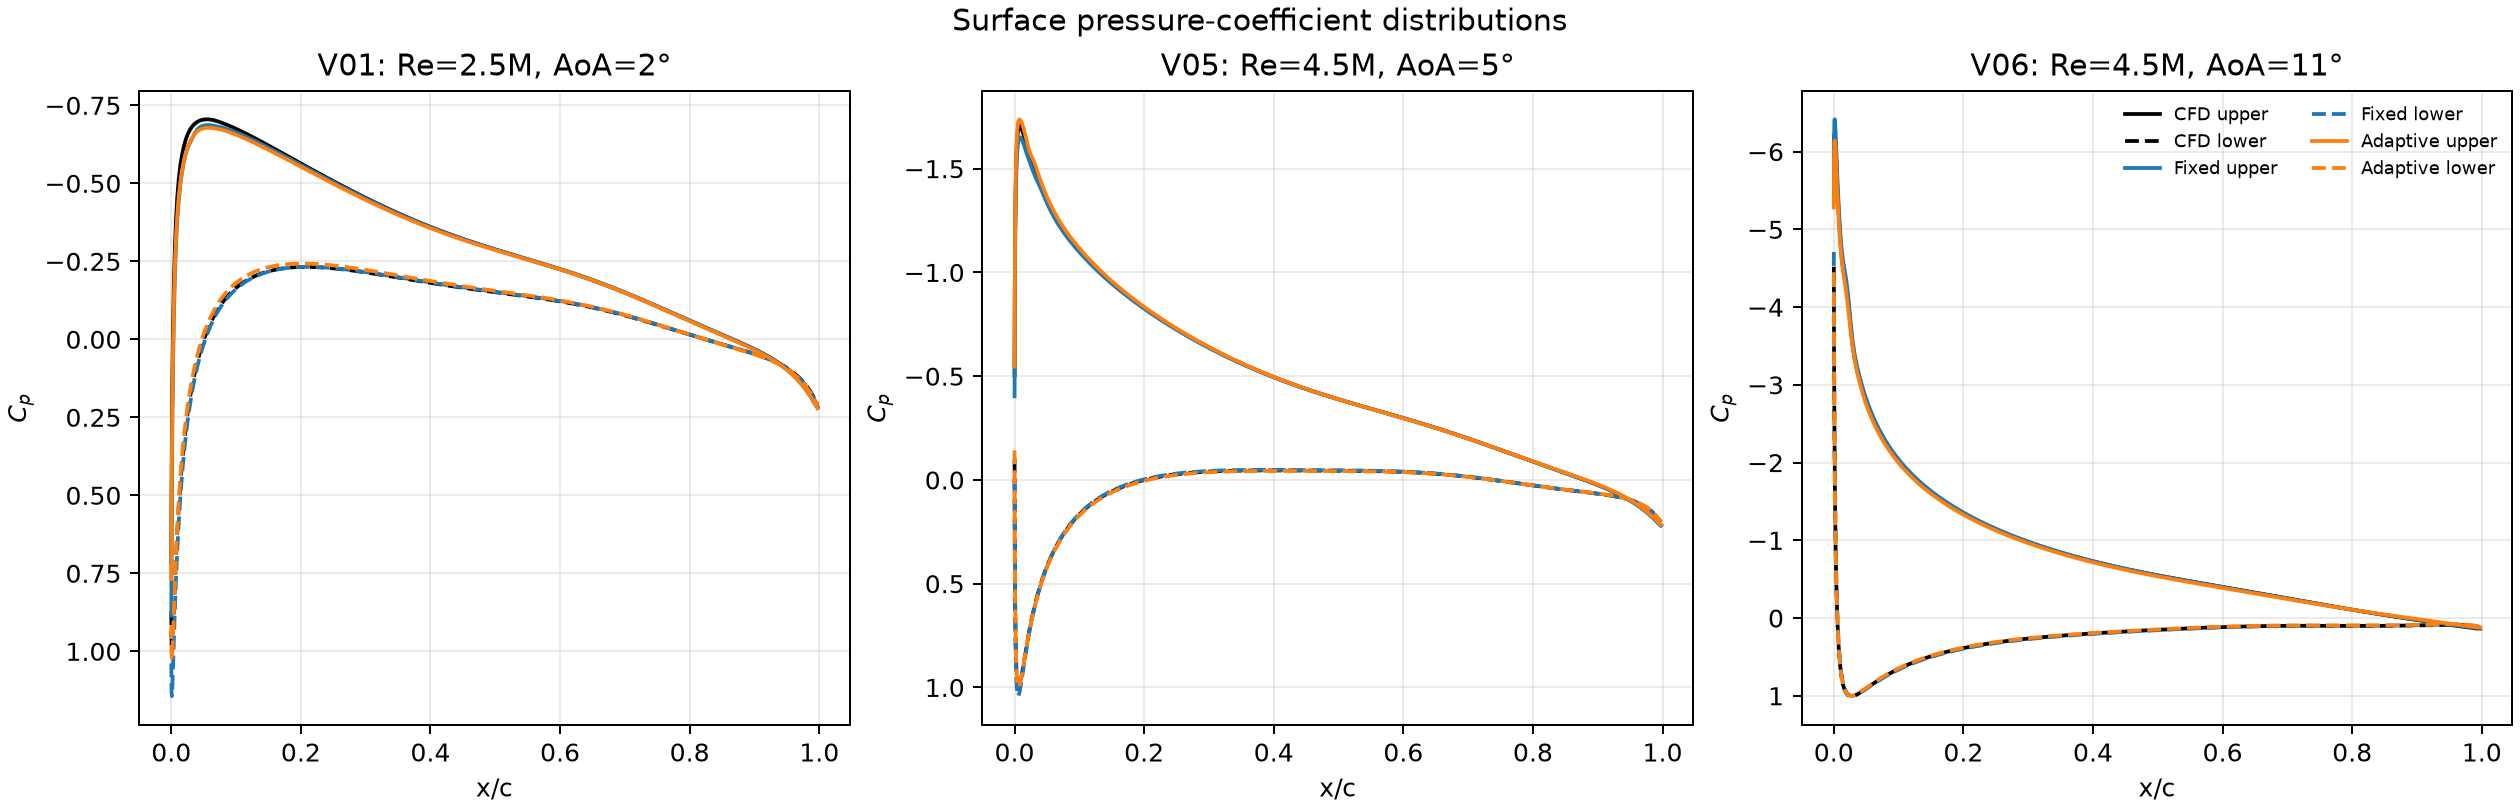

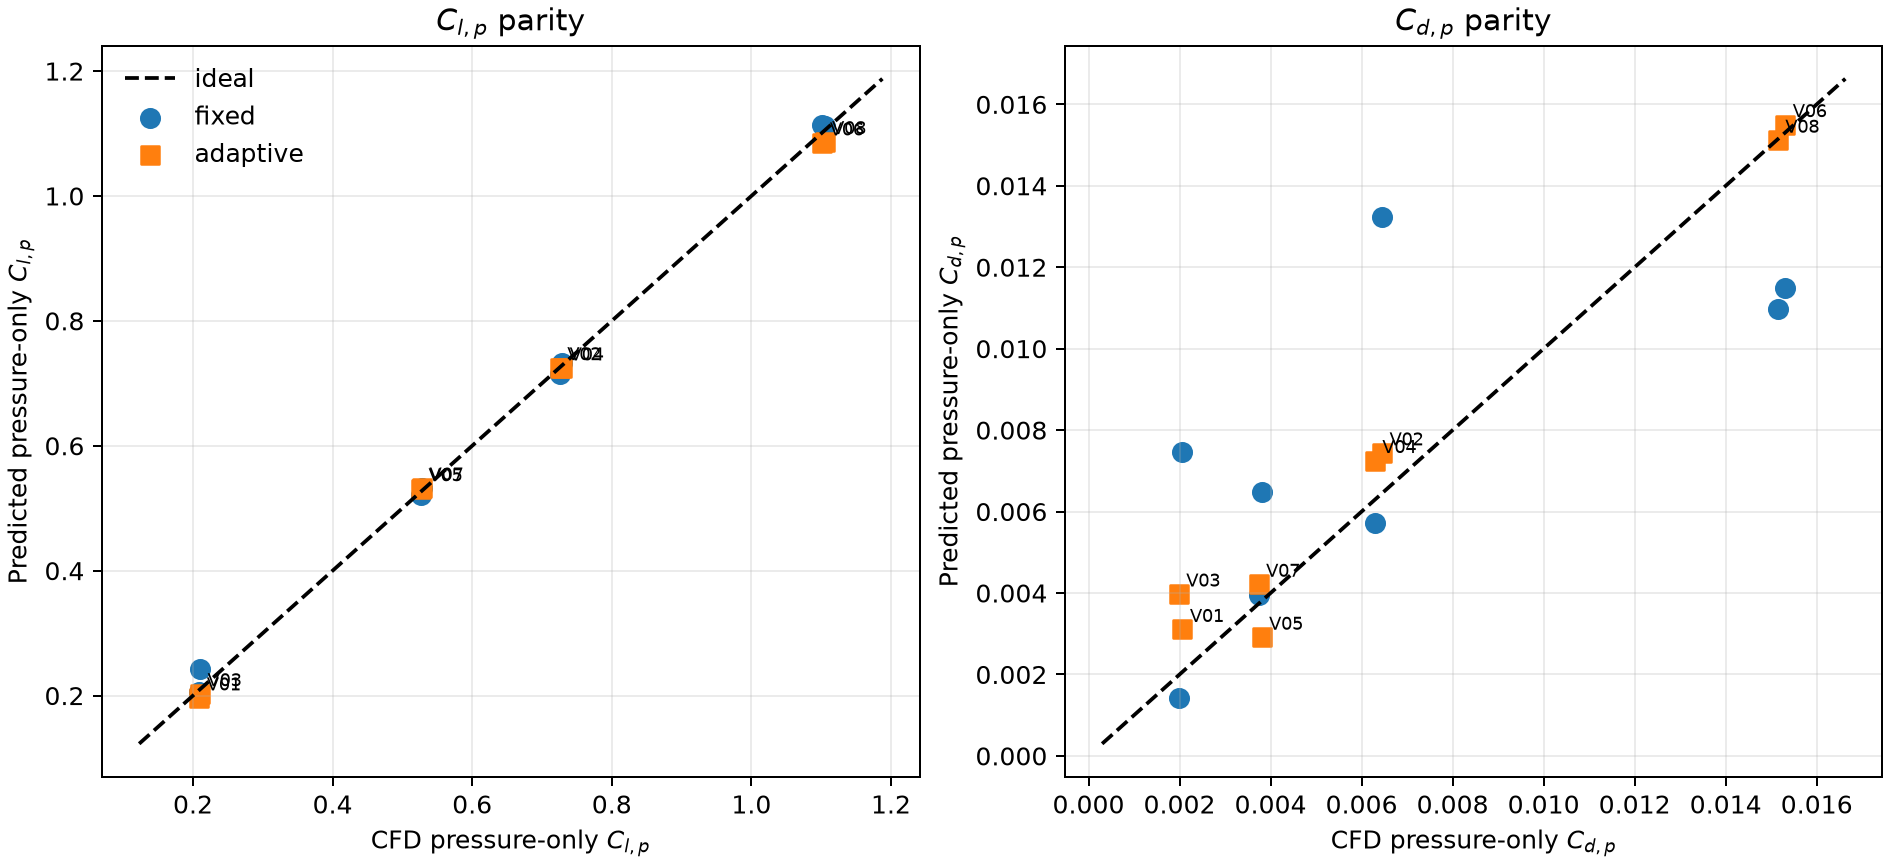

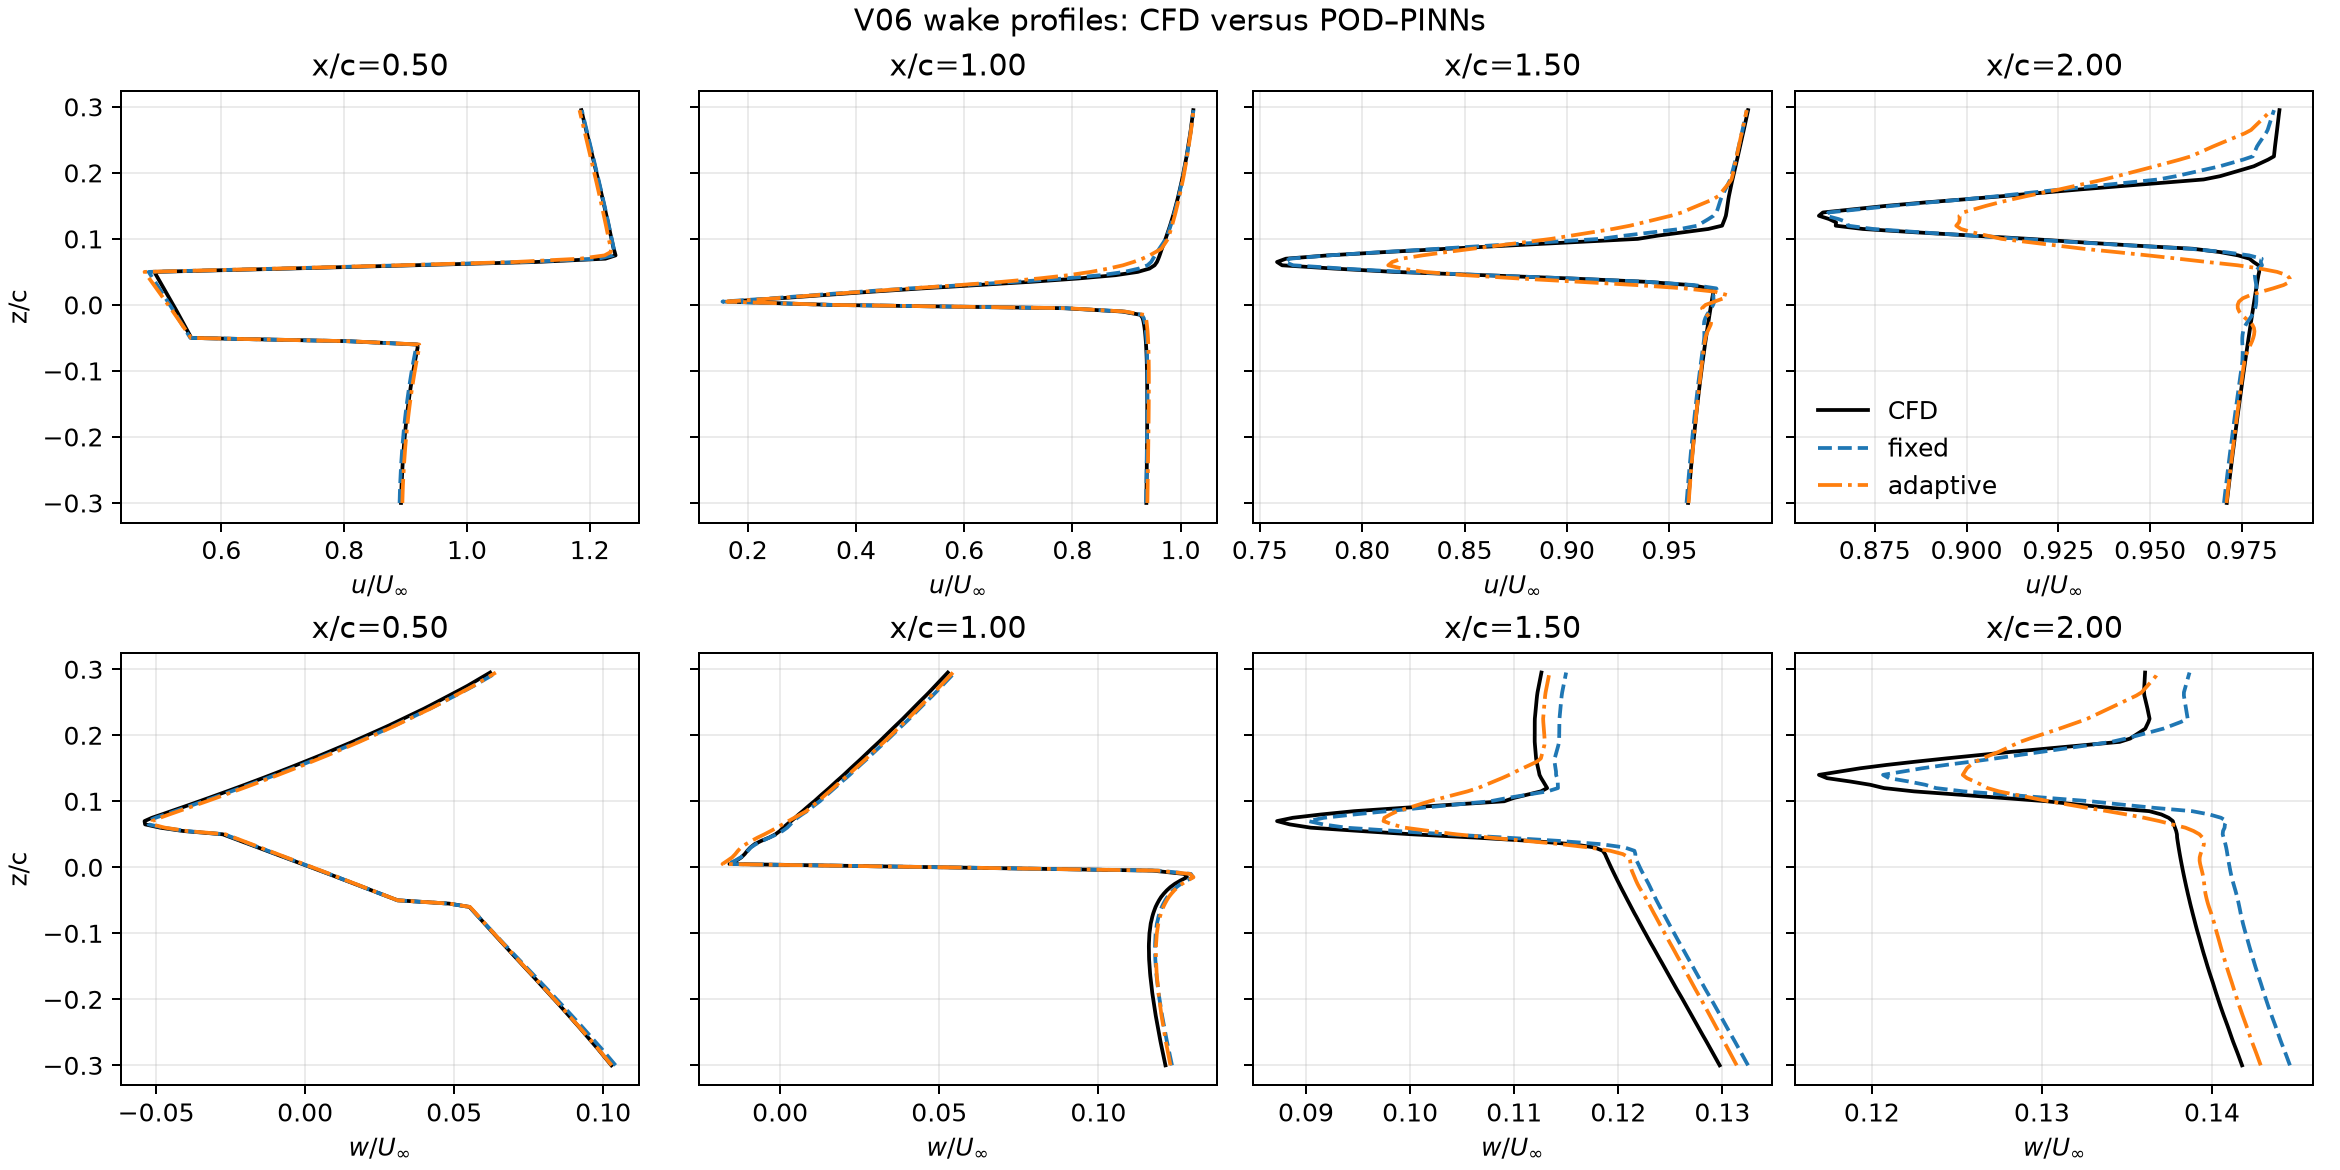

In [3]:
extended = PROJECT / 'artifacts/extended_analysis/figures'
display(Image(filename=str(extended / 'surface_cp_comparisons.png')))
display(Image(filename=str(extended / 'pressure_force_parity.png')))
display(Image(filename=str(extended / 'wake_profiles_V06.png')))

## 10. Case-wise and parameter-dependent validation

These plots show that the adaptive improvement is not uniform: some cases and fields improve strongly while others degrade.

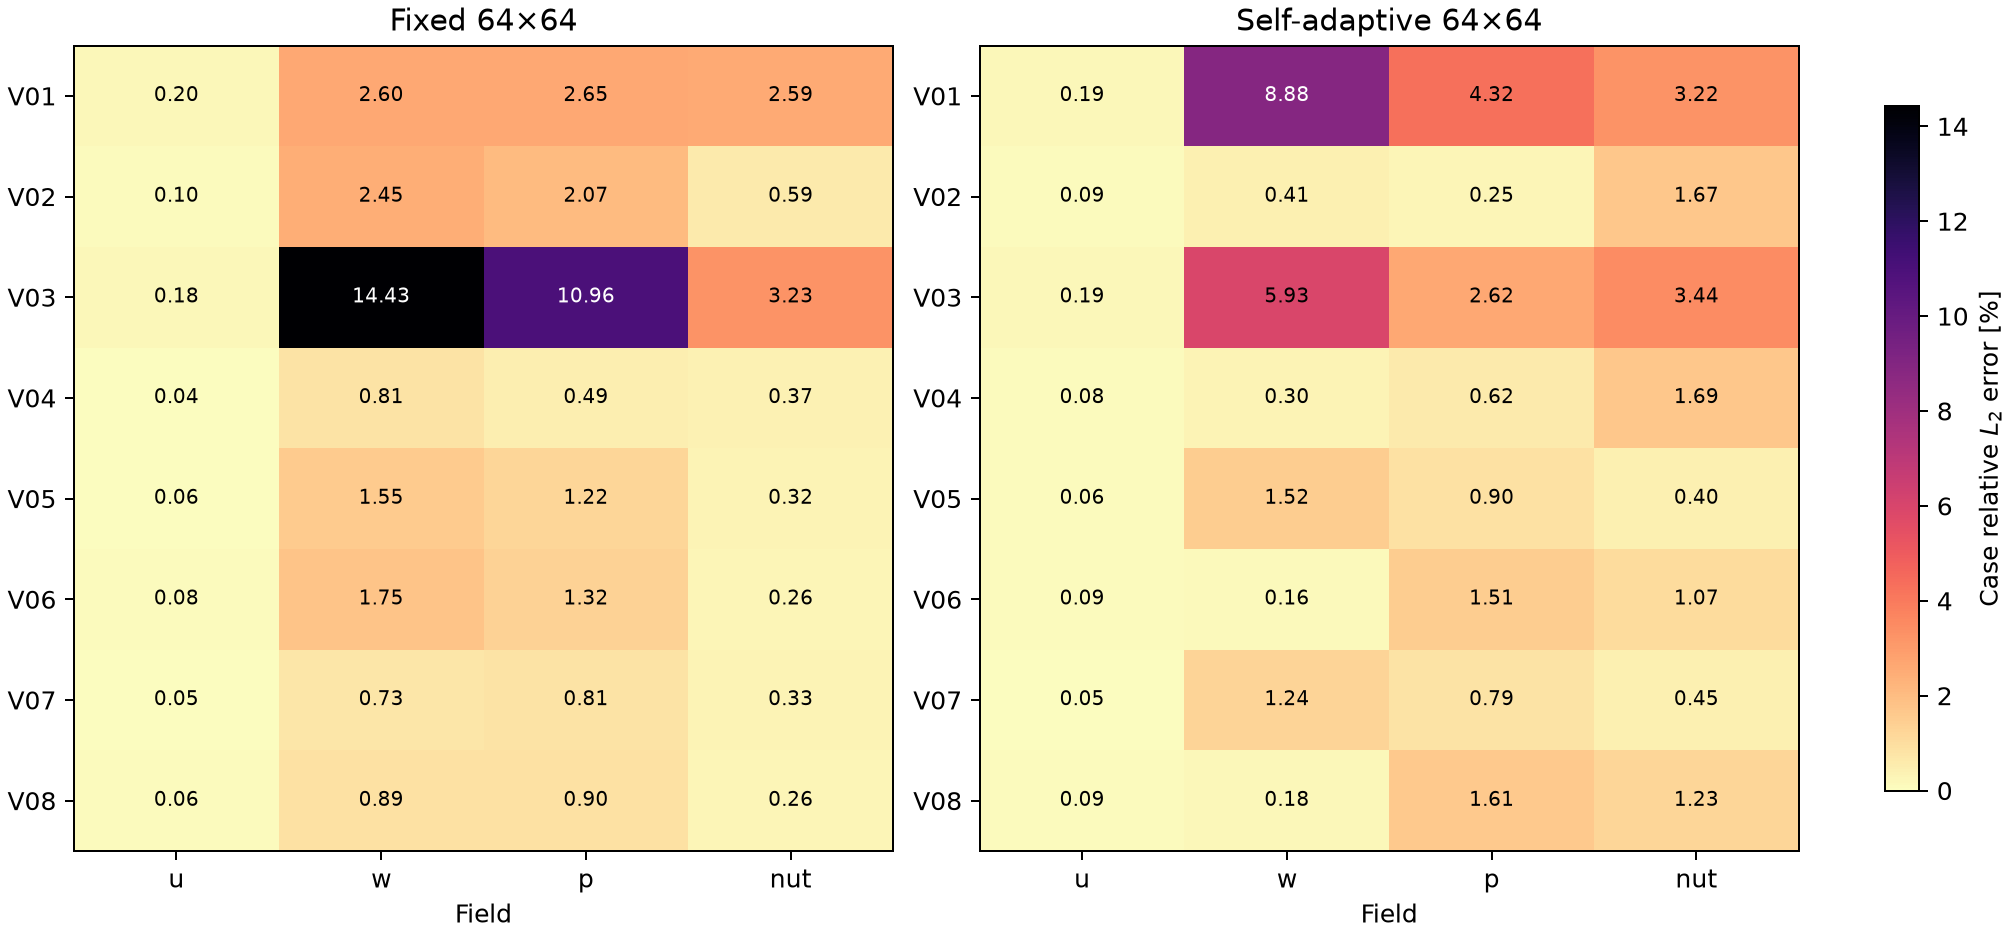

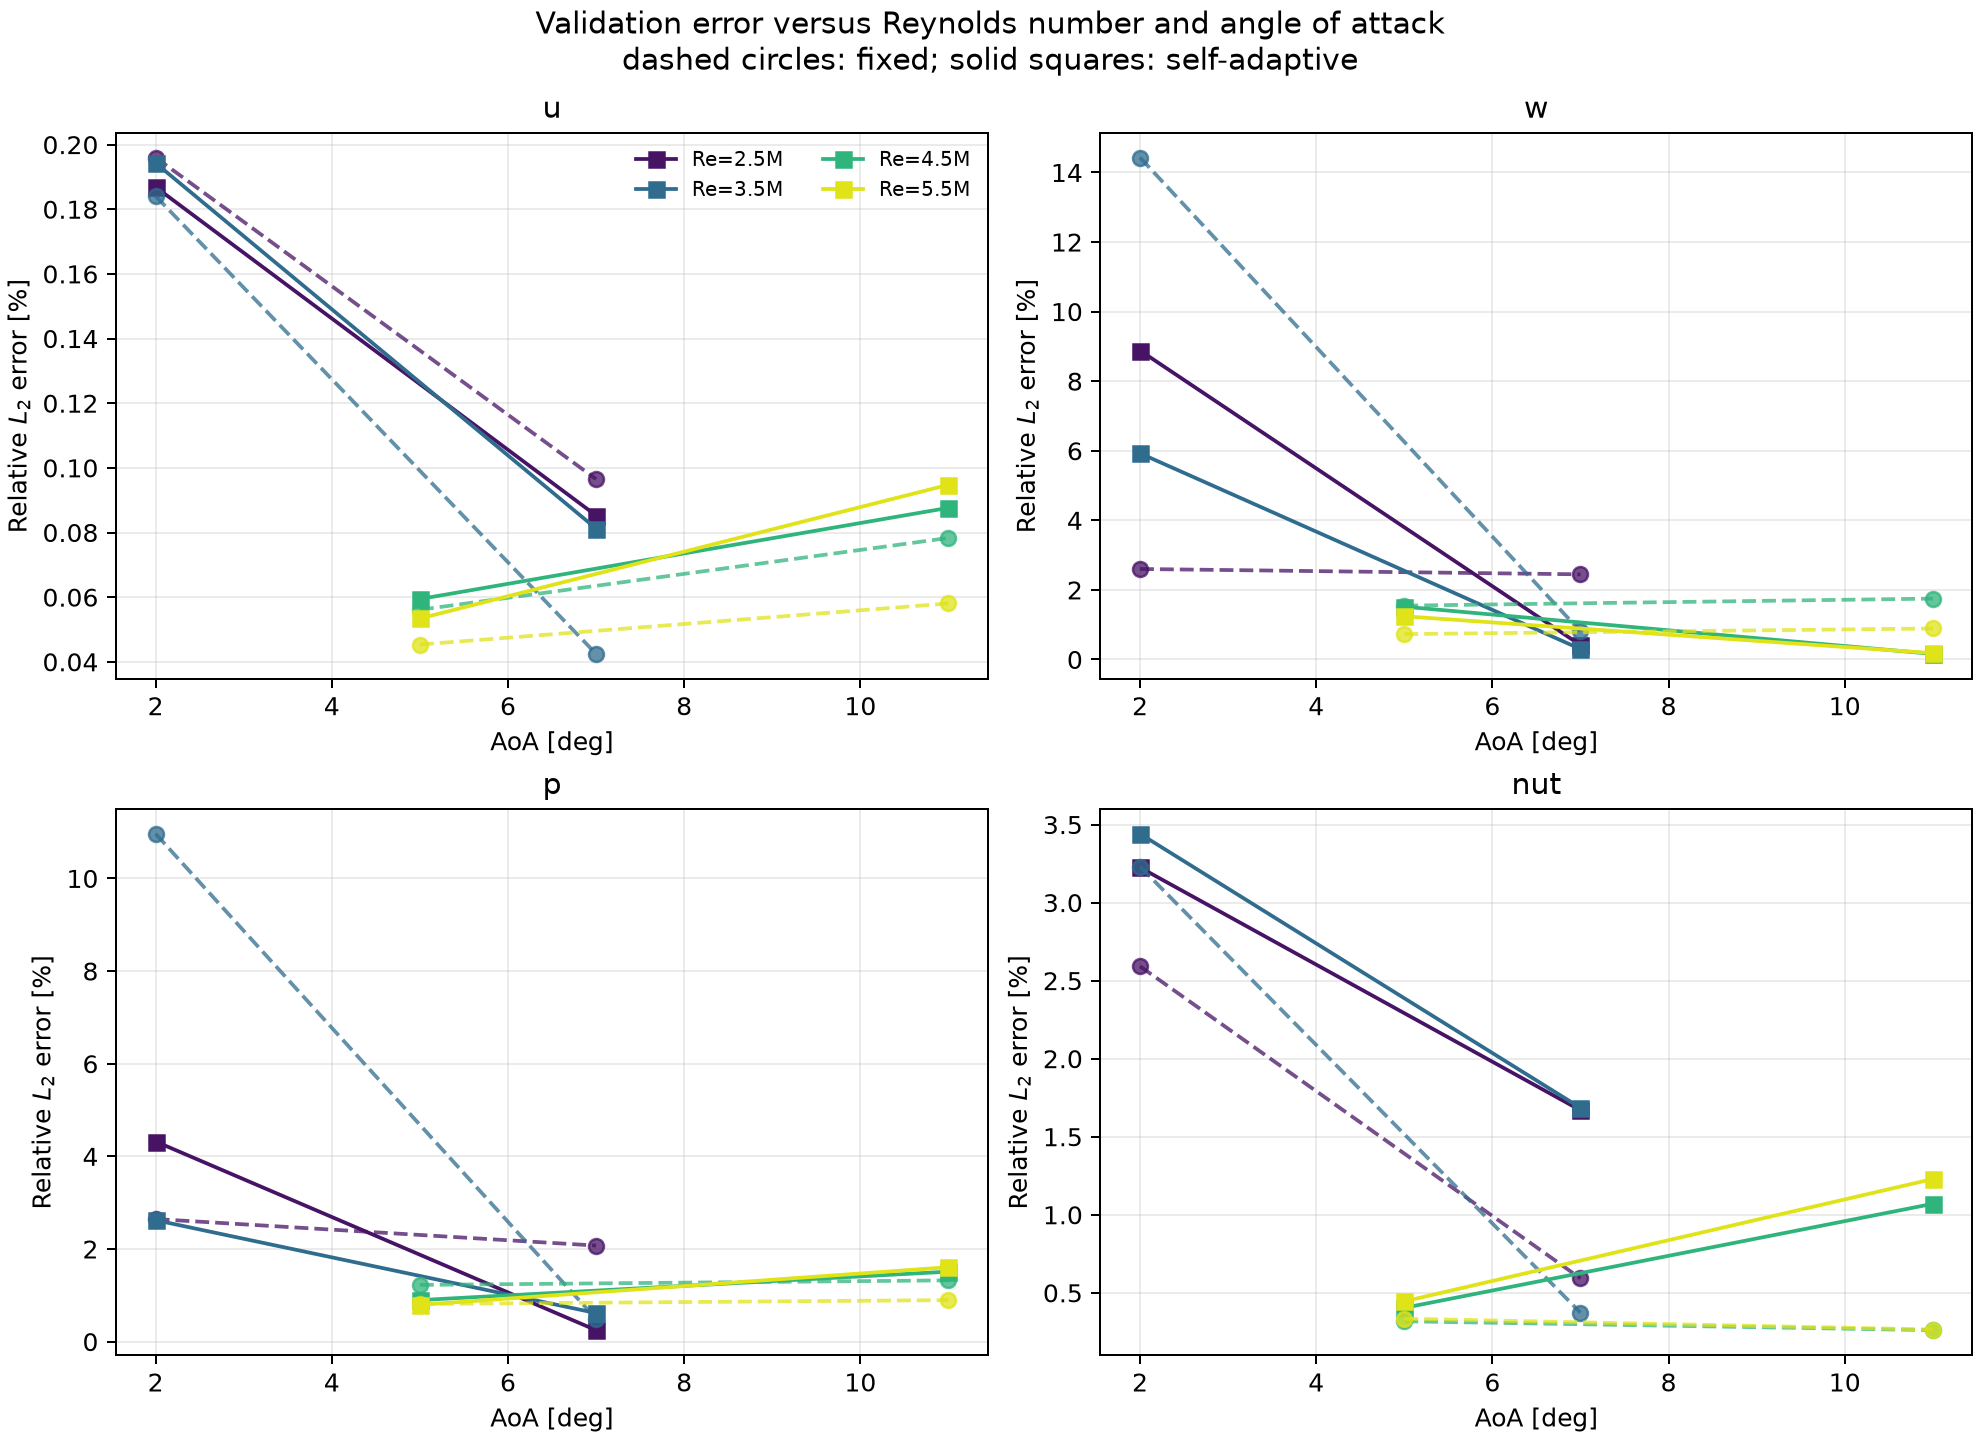

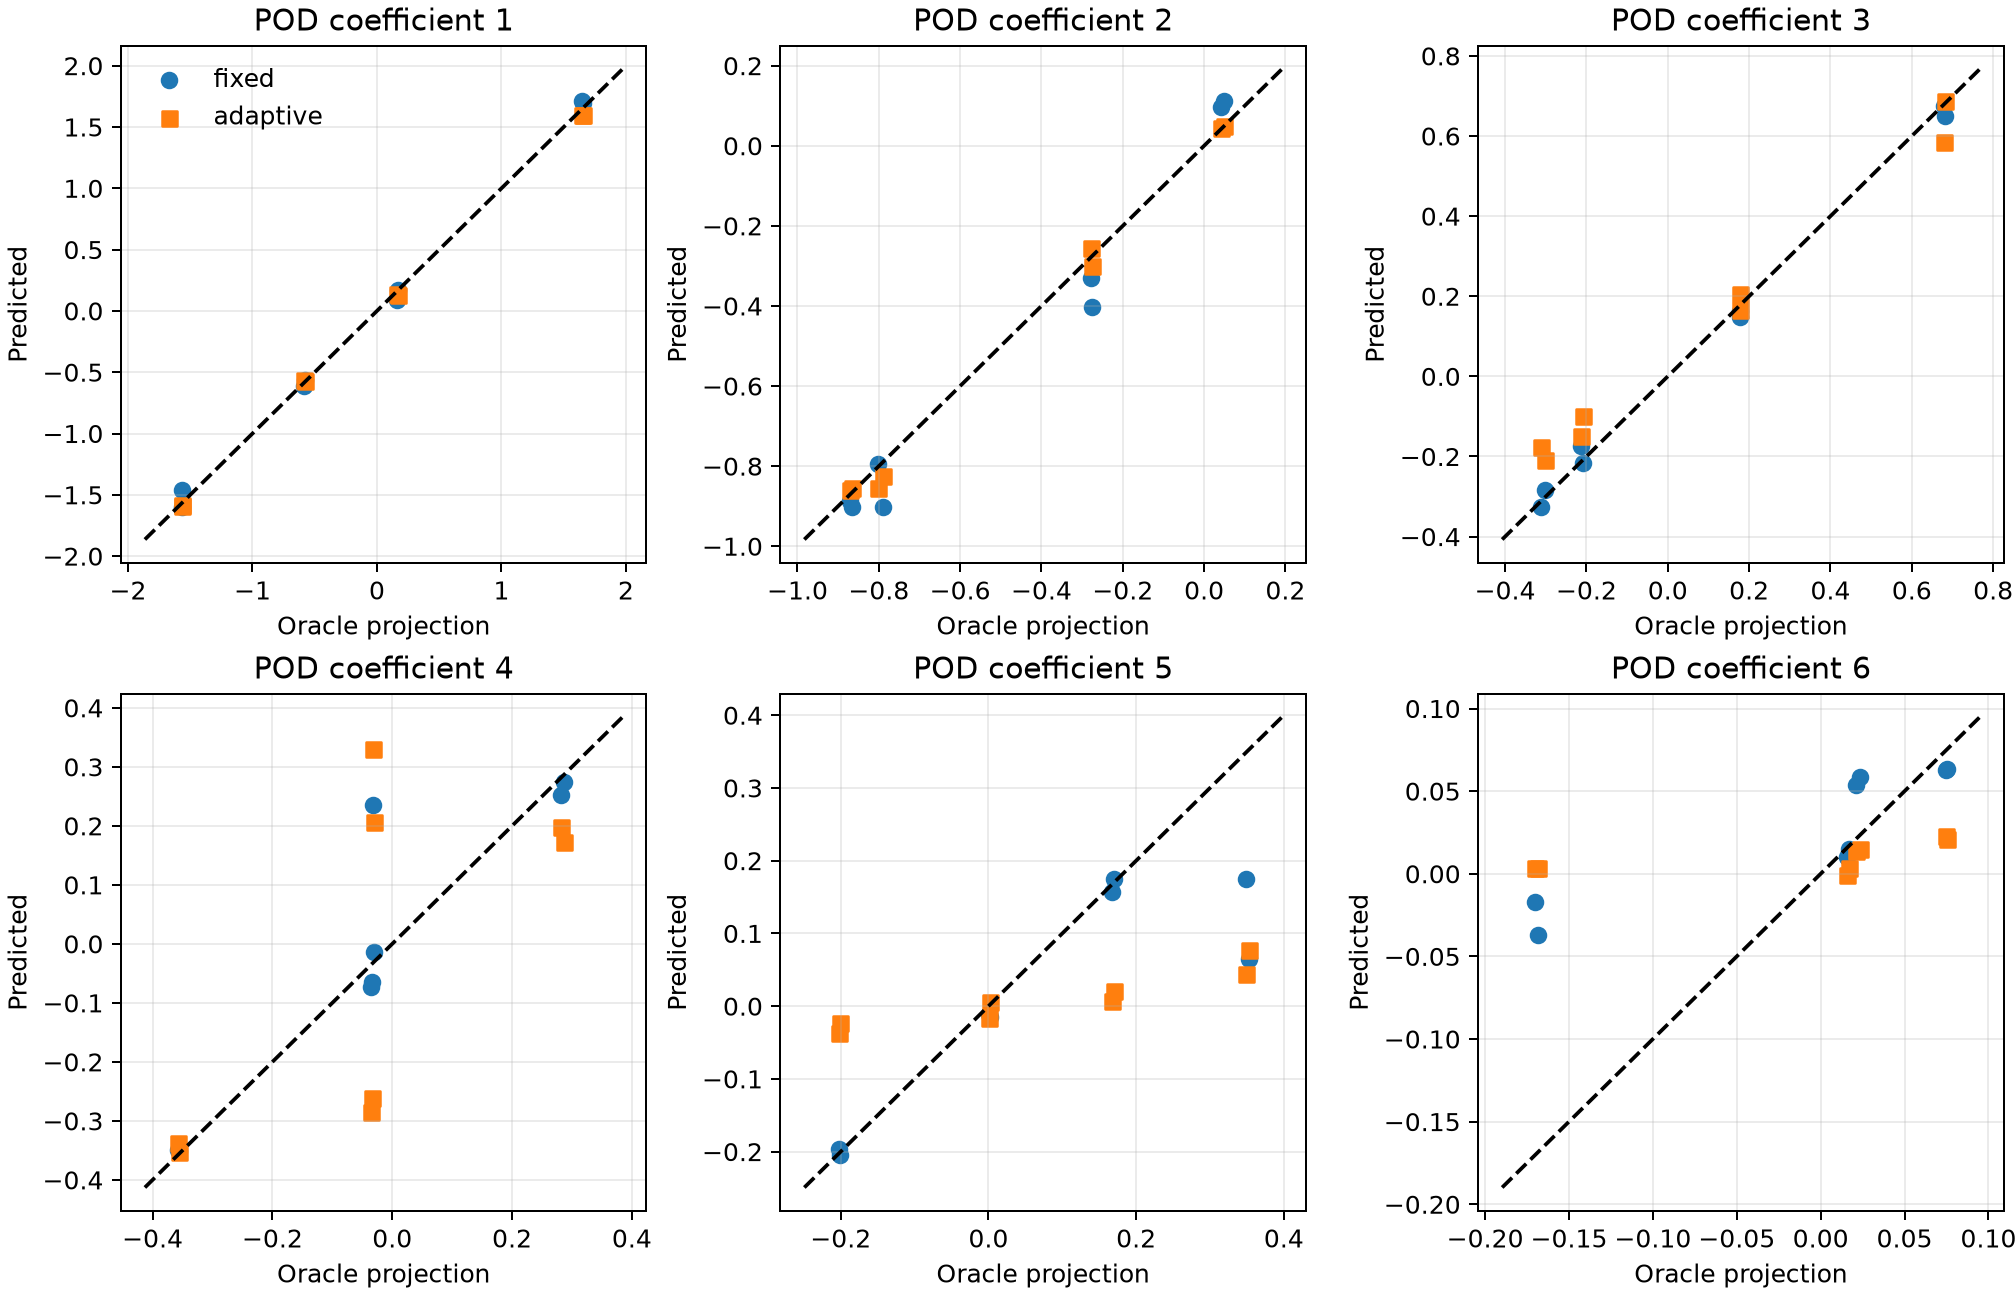

In [4]:
display(Image(filename=str(extended / 'casewise_error_heatmaps.png')))
display(Image(filename=str(extended / 'error_vs_parameters.png')))
display(Image(filename=str(extended / 'leading_coefficient_parity.png')))

## 11. POD structure and physical modes

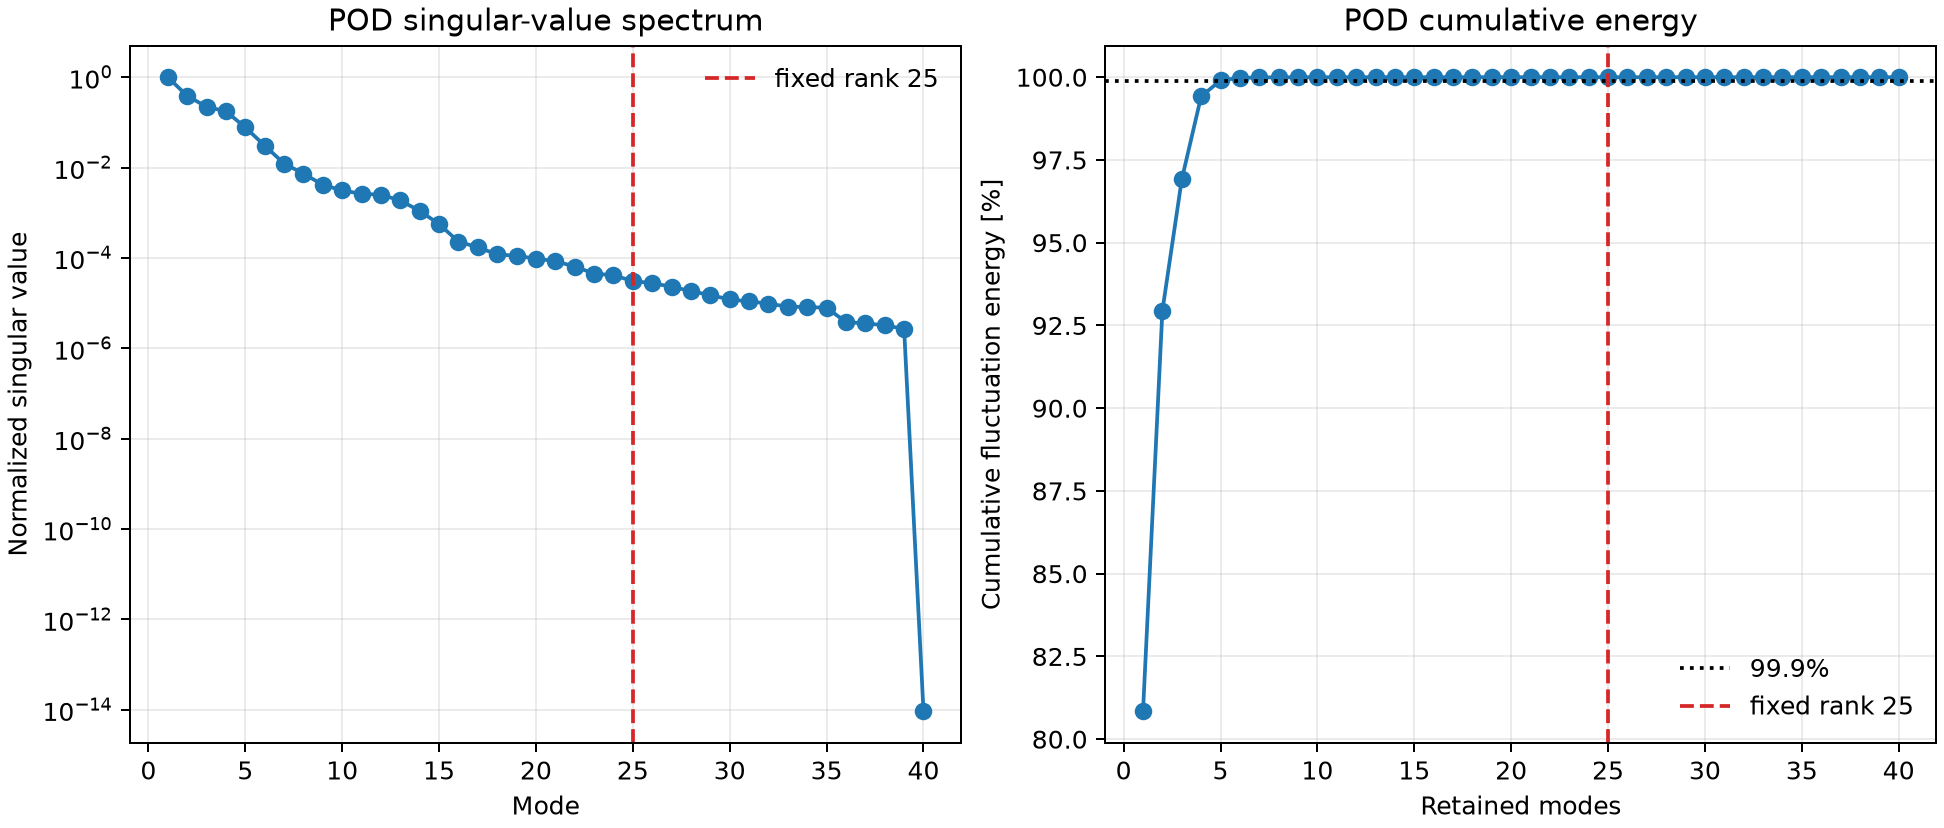

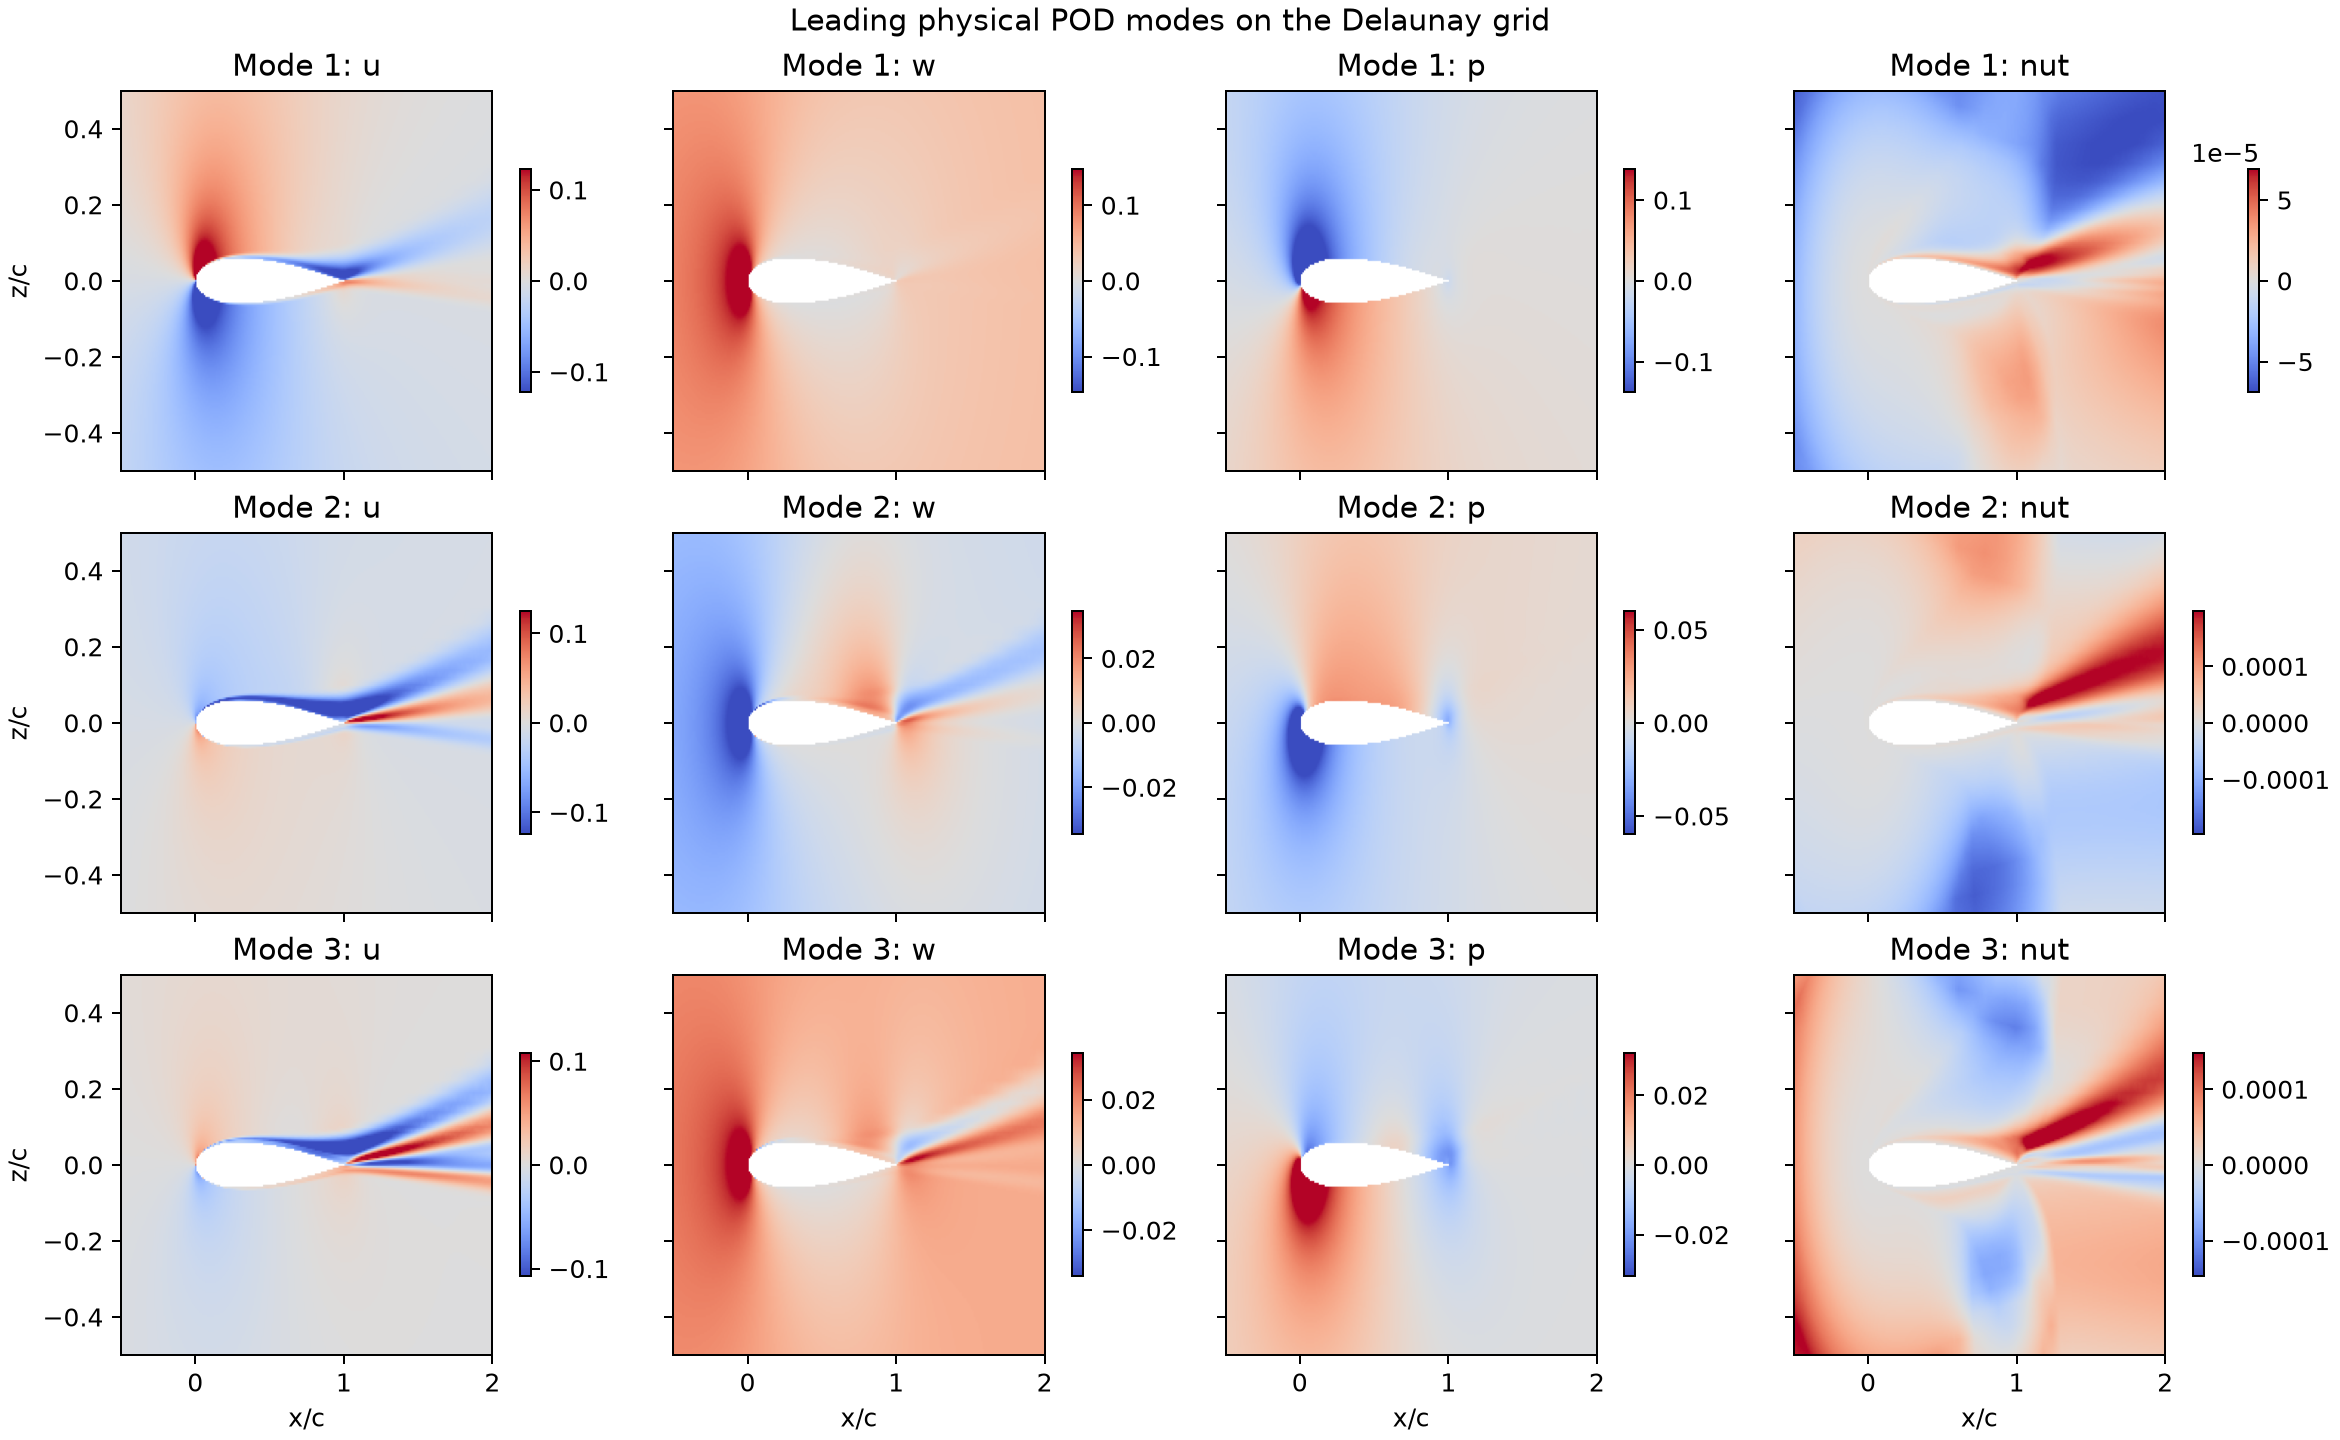

In [5]:
display(Image(filename=str(extended / 'pod_spectrum_and_energy.png')))
display(Image(filename=str(extended / 'leading_pod_modes.png')))

## 12. Spatial physics and representative held-out contours

Residual contours identify where the discrete PDE imbalance is concentrated. Three validation conditions show low-, medium-, and high-incidence field reconstruction.

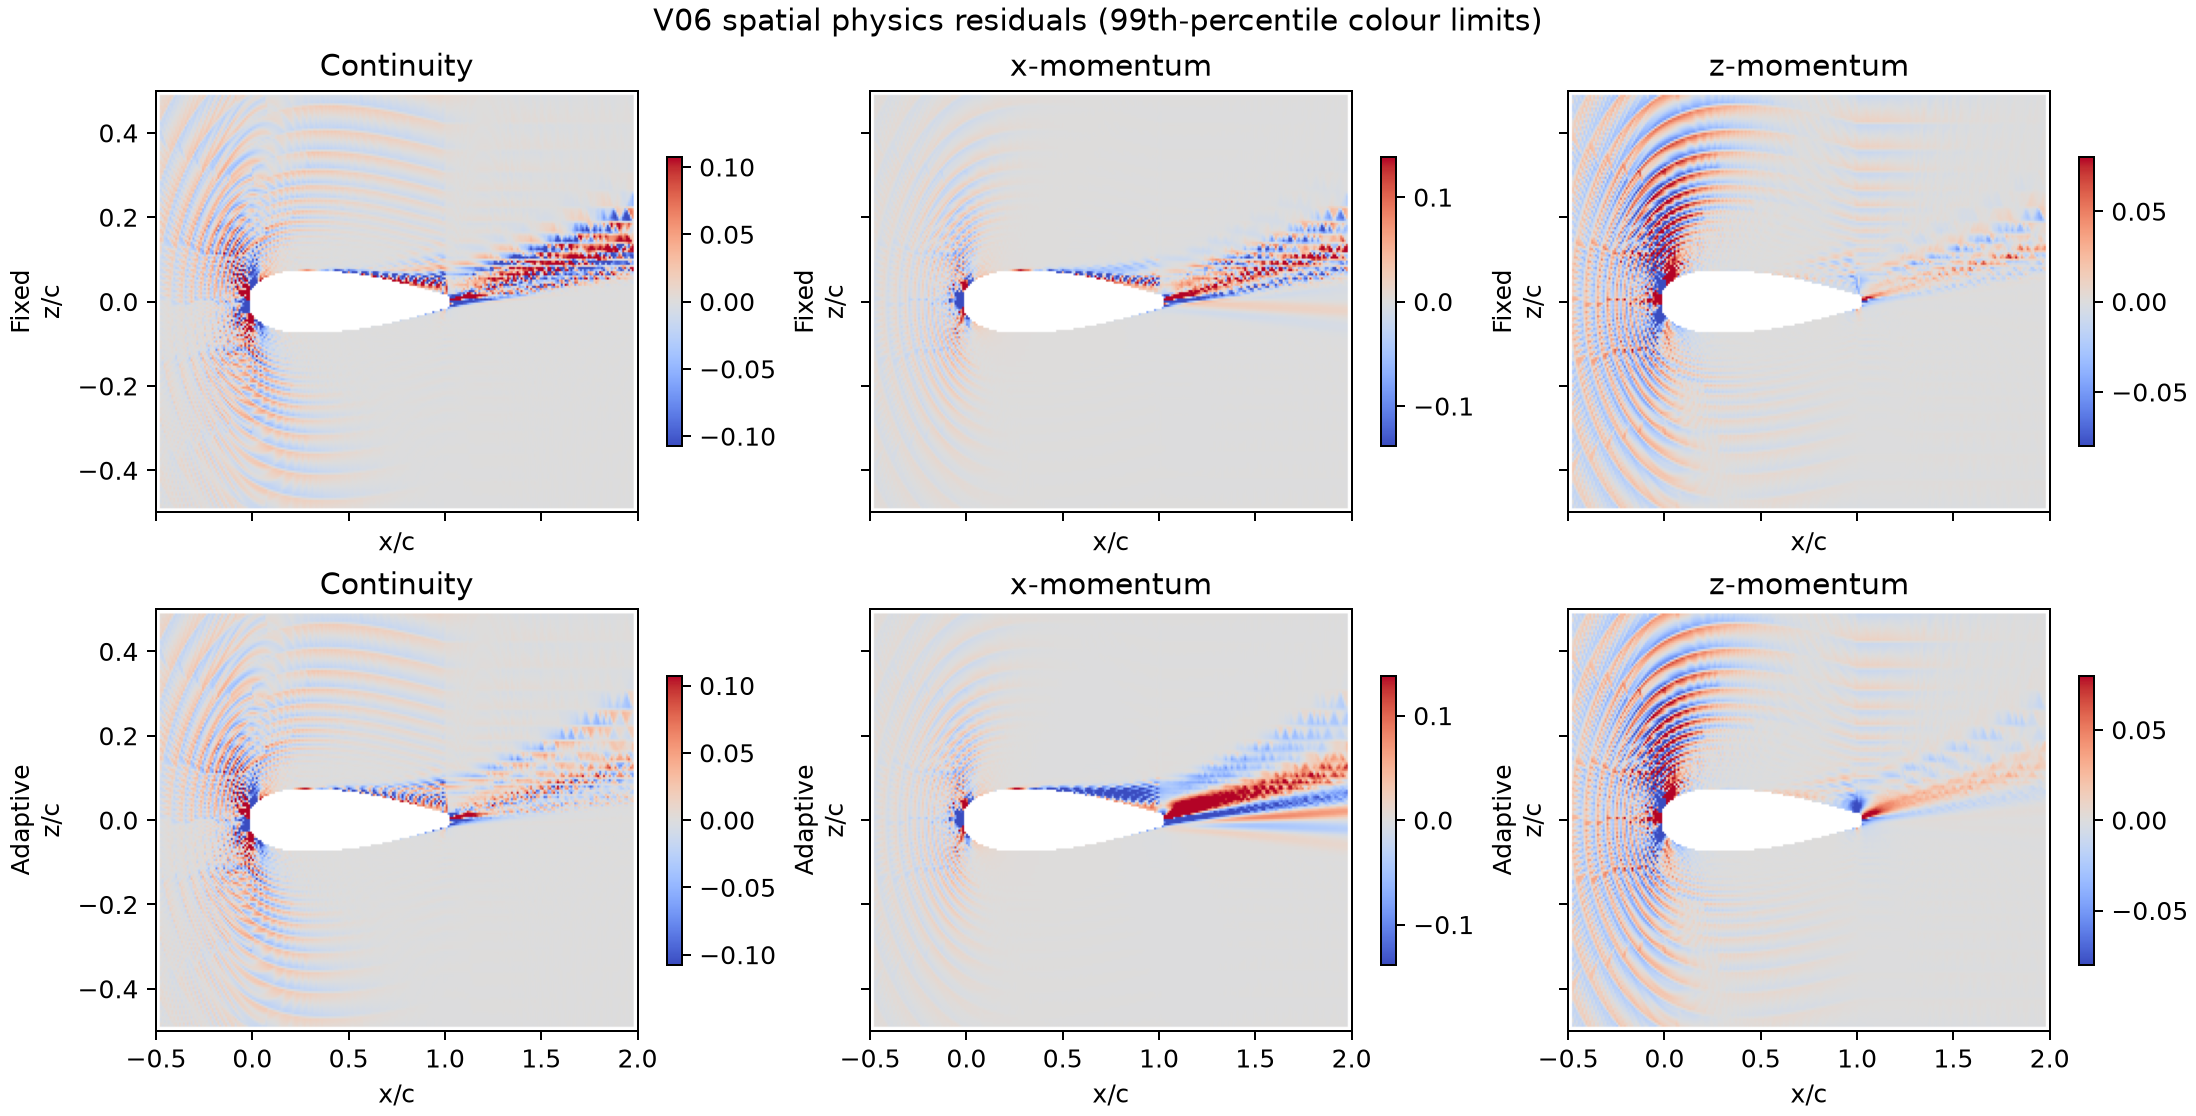

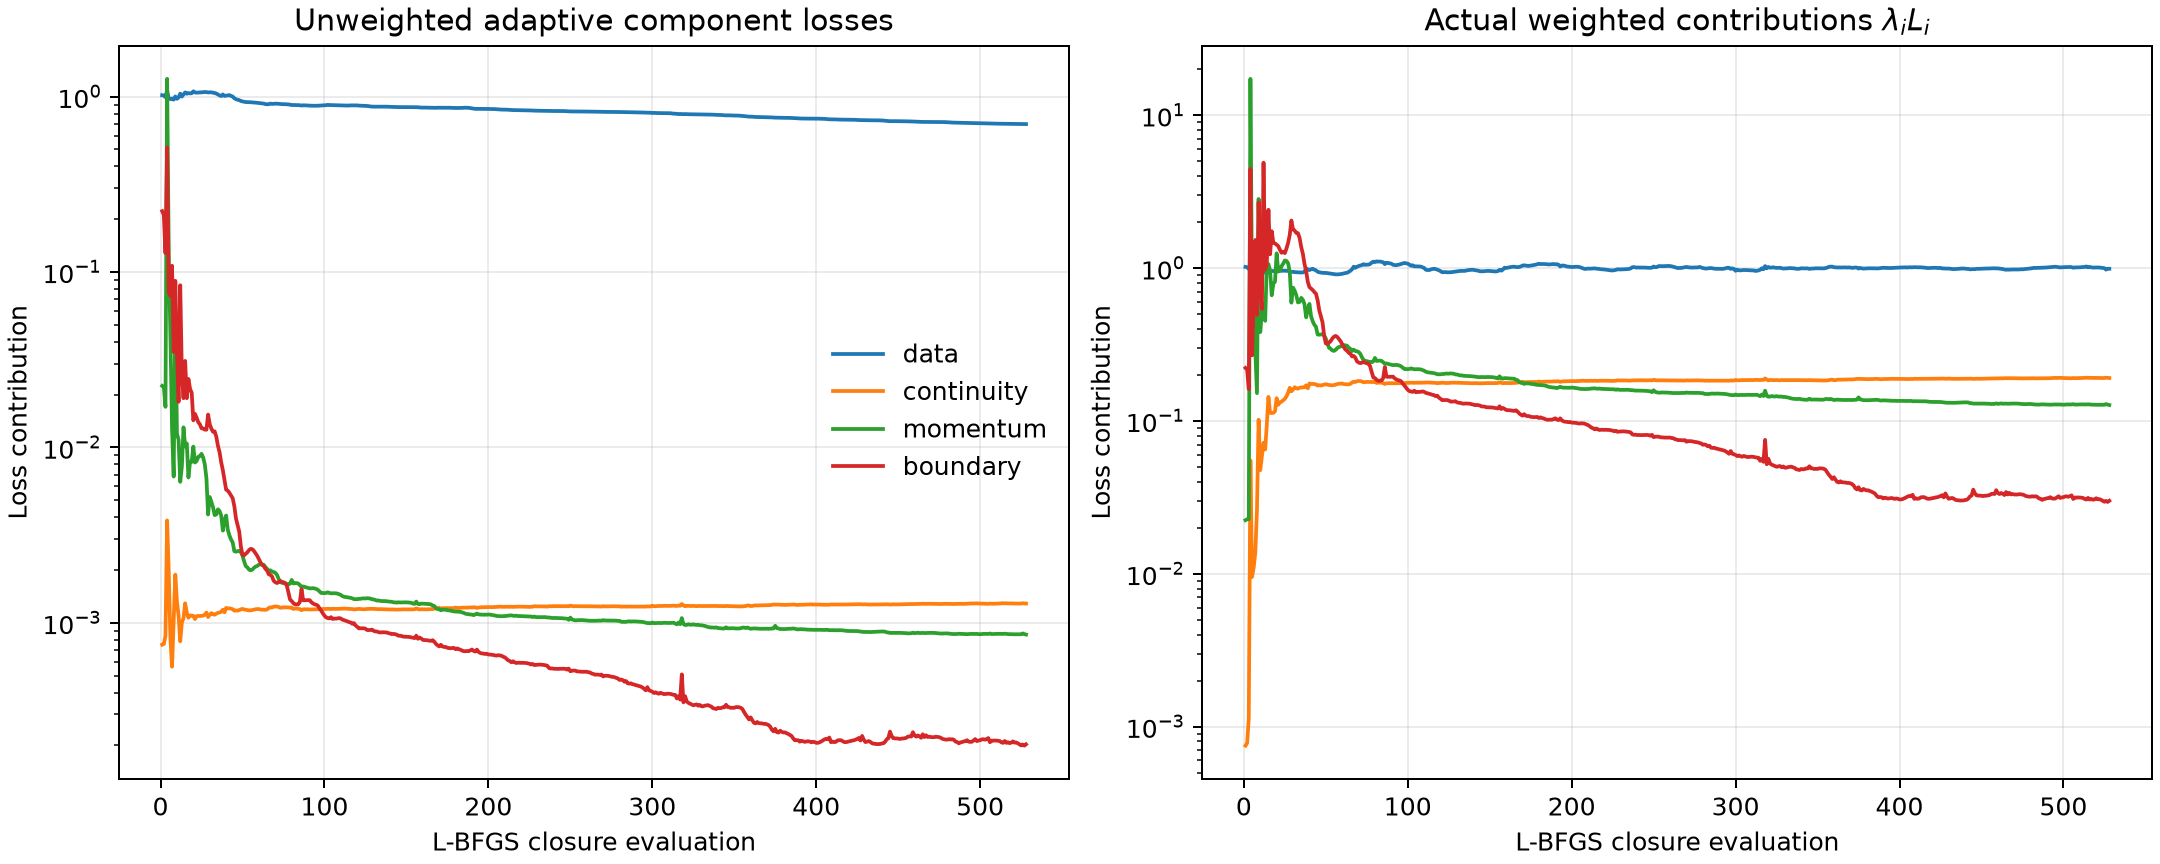

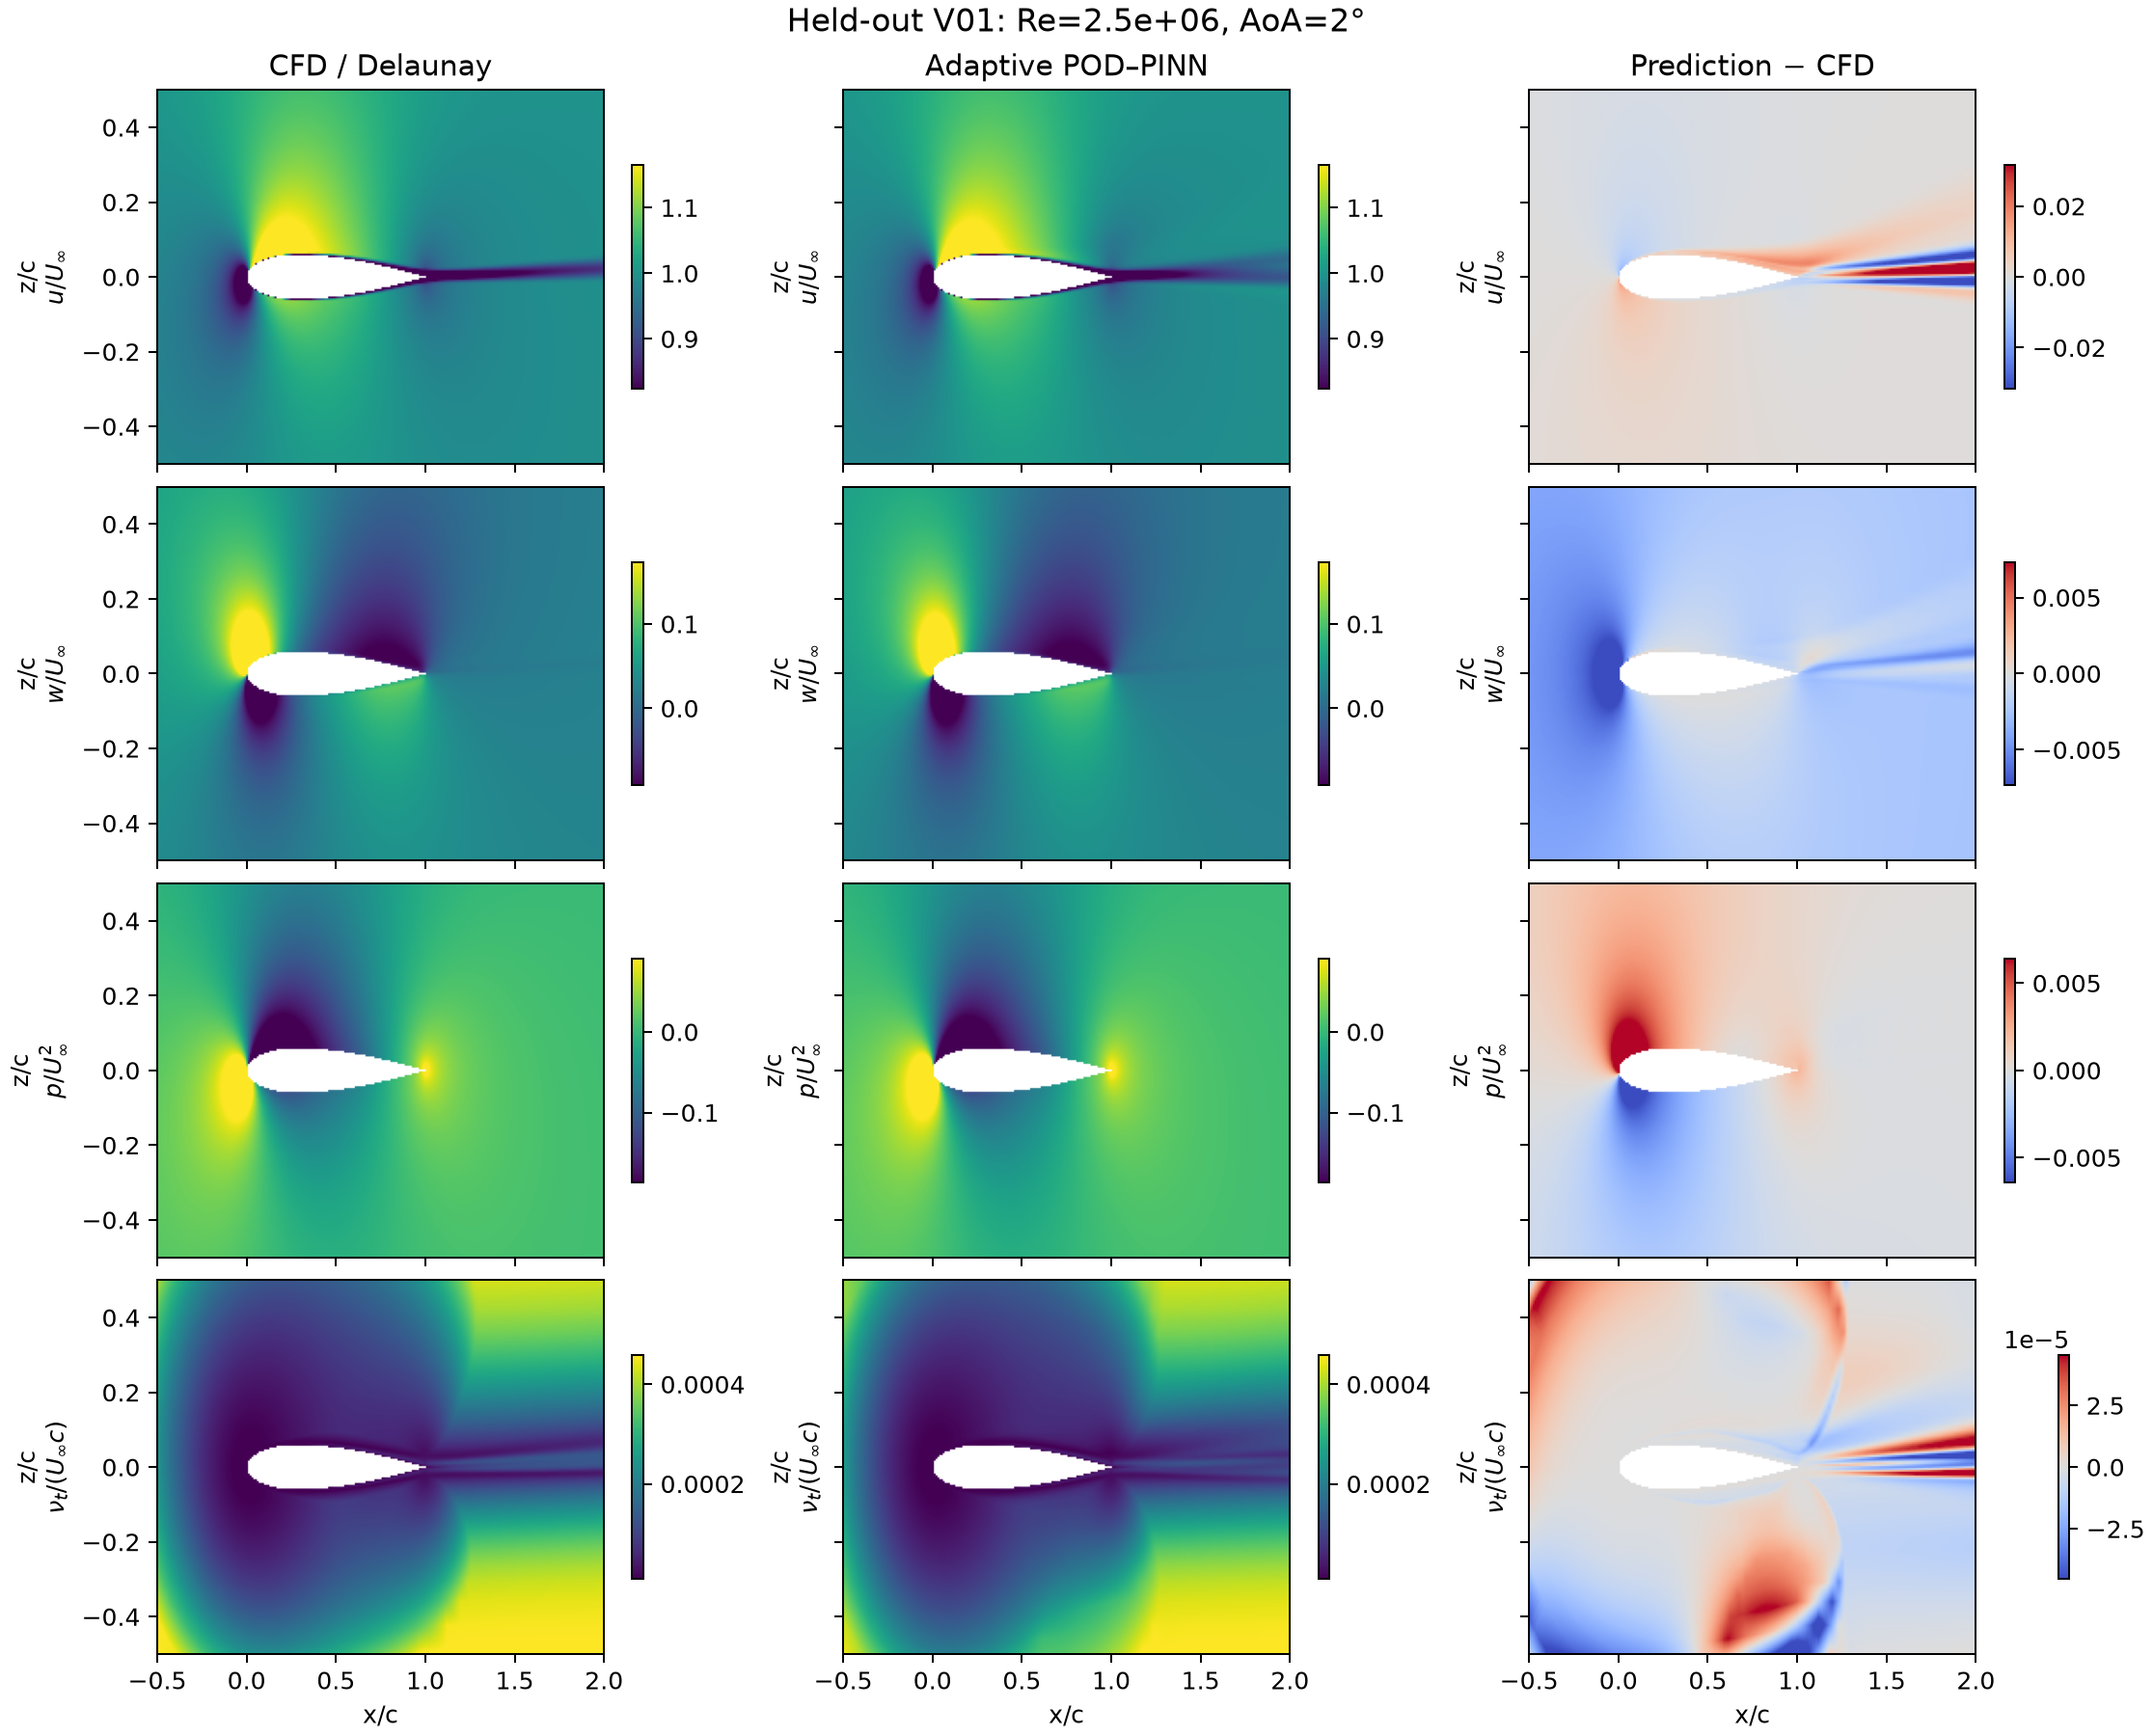

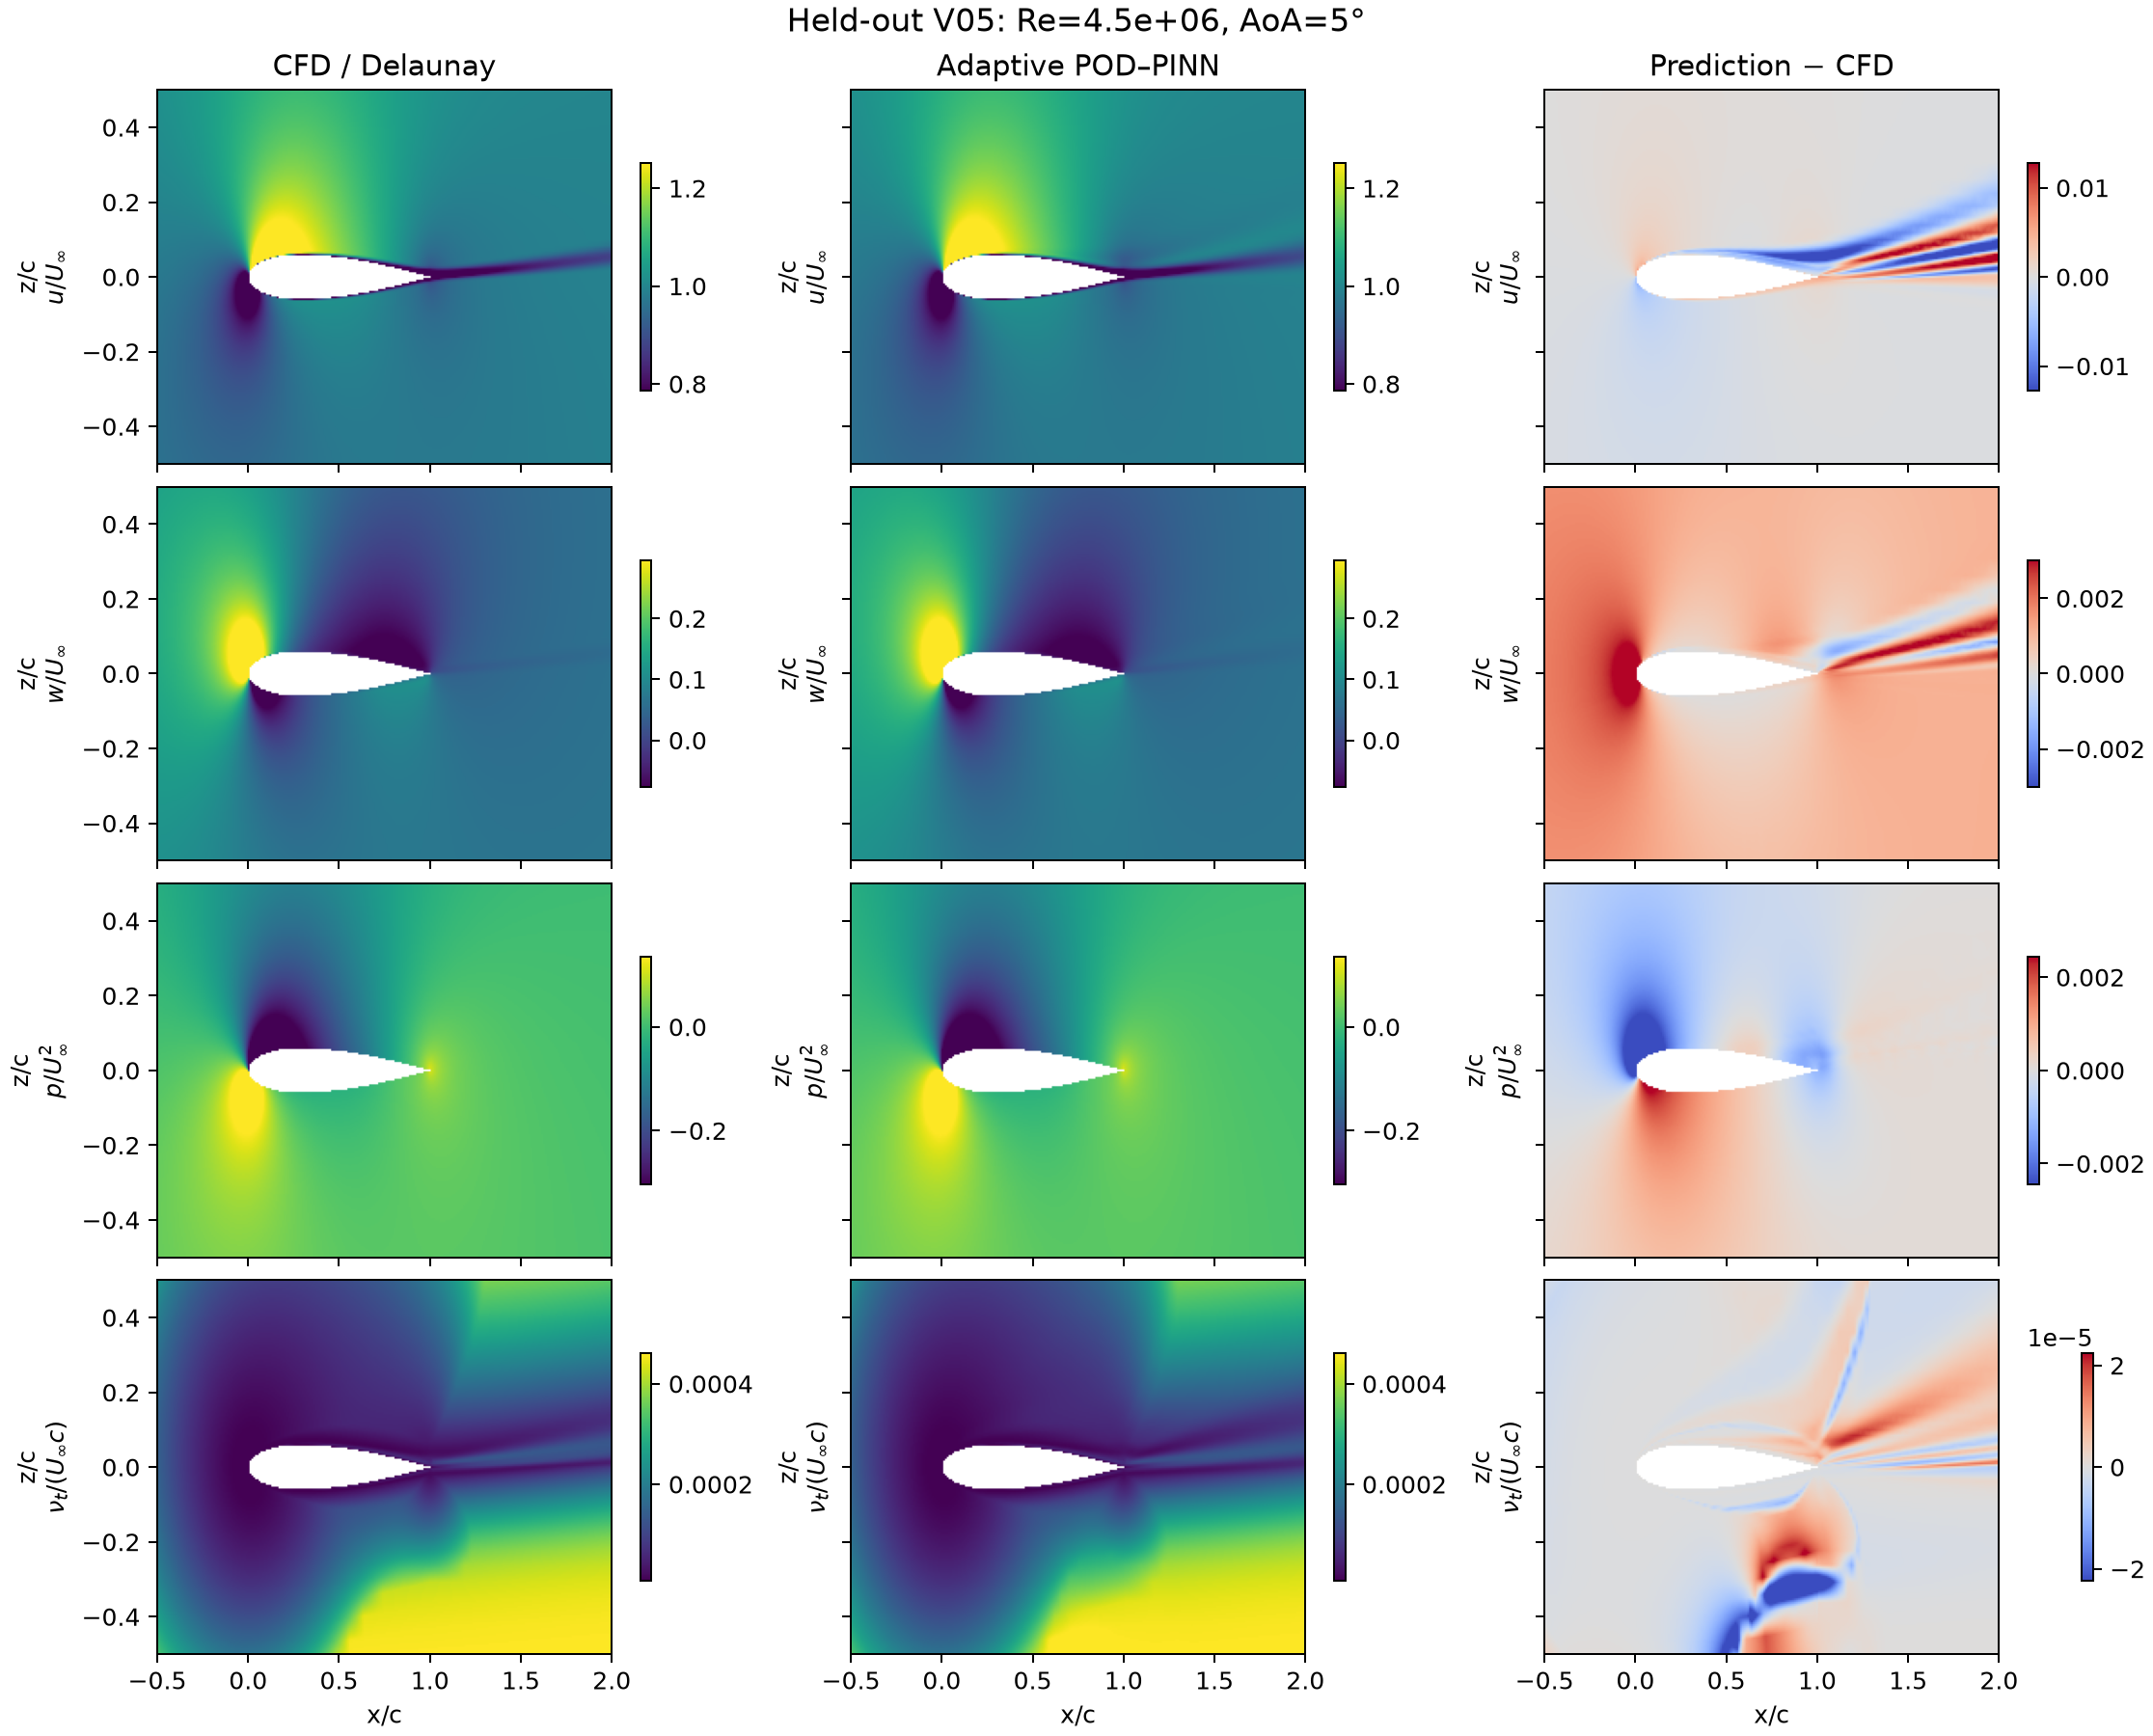

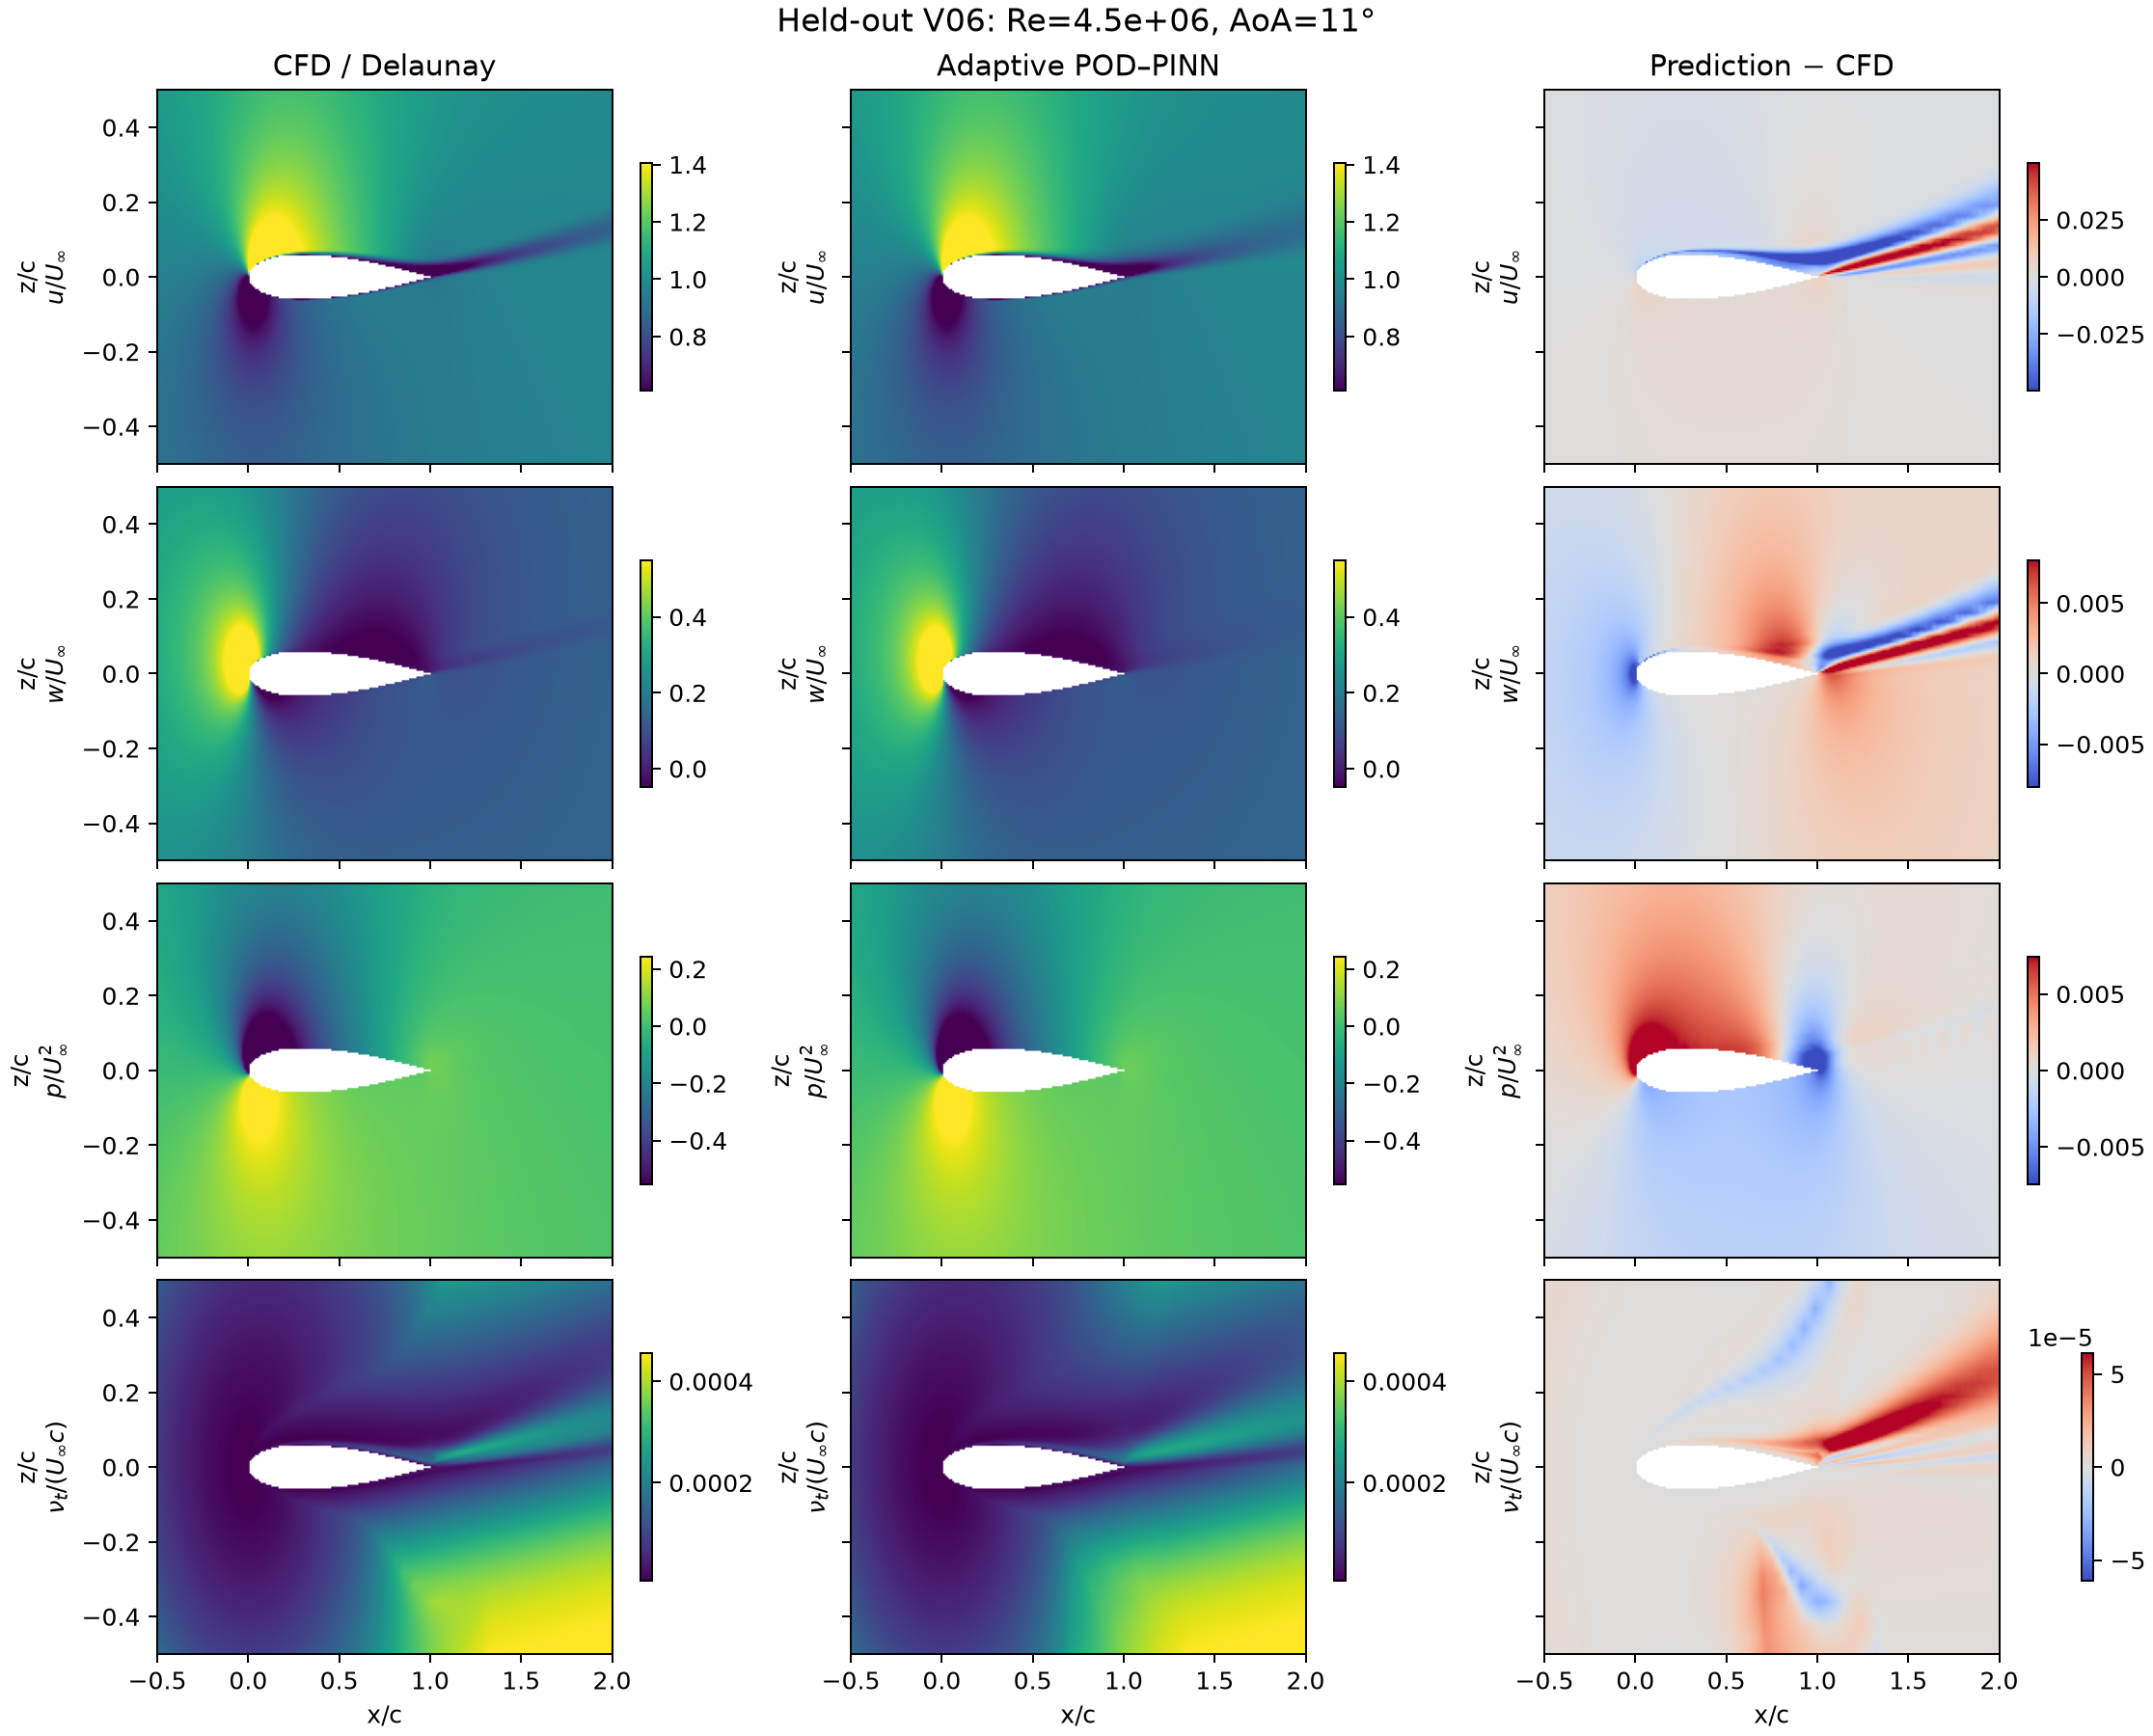

In [6]:
display(Image(filename=str(extended / 'spatial_physics_residuals_V06.png')))
display(Image(filename=str(extended / 'adaptive_loss_contributions.png')))
for case_id in ('V01', 'V05', 'V06'):
    display(Image(filename=str(extended / f'adaptive_contours_{case_id}.png')))

## 13. Engineering interpretation

The fixed 64×64 model is the clean baseline. The self-adaptive model lowers mean held-out field error from 1.426% to 1.180%, mainly through better `w` and pressure predictions. It worsens `nut` and x-momentum slightly. The physics/boundary weights reach the imposed stability ceiling, so this must be reported as a bounded adaptive solution.

The structured-grid residual excludes the wall-adjacent 0.02c band, and force metrics are pressure-only. Full limitations and interpretation are in `COMBINED_ENGINEERING_REPORT.md`.